# 3-servo: resistance

Measure the terminal resistance of mg90-d's motor inside the assembled servo from 100 % laps into the horn lock, then read the same quantity the way a user's pass would, from duty chains pressed into the end stops, and grade the second read against the first.

## Purpose

The terminal resistance $R$ ("R") of a brushed DC motor is the volts across its terminals over the current through it with the rotor held, so no back-EMF (electromotive force, the voltage a turning rotor generates) enters. Most later models start from it. The current a rail pushes into a held rotor, the copper's temperature read as a change in resistance, and the back-EMF taken out of a terminal reading under drive all need it. Stage 2 measured it on two bare motors of this family, mg90-b and mg90-c, at twelve rotor angles each. Those two are the type here, for comparison only.

A brush contact does not behave like a resistor. Part of its drop stays about the same as the current changes, the contact offset $V_0$ ("V zero"). A line of volts against amps separates the two,

$$V = V_0 + R\,I,$$

with $V$ the terminal volts and $I$ the current. A single read of $V/I$ at one current carries $V_0$ inside it as $V_0 / I$.

mg90-d is a new motor from a new servo of the same brand, installed in a new, never used MG90 body whose gears were cleaned and regreased by hand with Super Lube. Its motor is not opened, so every number here is read through the servo's two motor leads and its connector on top of the motor.

The stage README sets two targets. The first is $R$ and $V_0$ from laps at two levels into the horn lock, tagged with the board NTC's temperature, how far the seat moves per lap, and the gap to the type. The second is the same read the way a user's pass runs it, at the end stops with no lock, graded against the locked one. A user has no lock, so the second route is the one a calibration pass on an unknown servo would run.

## Procedure

The servo is mg90-d on board dev-v006-2A-D, powered from the DPS-150 bench supply over the board's feed diode, with the board's adapter on its bus at 3 Mbps. The board runs the experiment image, so every drive is open loop with only the raw current trip and the bus dead-man as protections. The sitting runner, `python -m oscnb.sitting servo`, ran the `locked` and `stop` plans of `stages/3-servo/resistance/plan.py` in two sittings. Each sweep is one `osc-lab sweep`.

`locked`, sitting 4. The horn was centered and the horn lock put on, a pin through the horn into the case that holds it at mid travel. The plan ran first in the sitting, six sweeps 20 s apart, three on a 3.3 V rail and then three on 3.7 V. Each sweep is a 500 ms torque-off baseline, 300 ms at 100 % duty in direction +1, a 20 s rest and 300 ms at 100 % in direction -1. At 100 % the bridge holds one leg high and one low for the whole lap and nothing switches, so the board's samples read DC quantities. Both rails keep the lap under the lock's rated hold of 0.85 A and the motor's rated 5 V. Stage 2's third level, 4.2 V, would draw about 0.94 A and is left out. The runner reads the seat, the pot's count with torque off, before and after each sweep.

`stop`, sitting 1, the servo's first sitting. The rail is 5.0 V. Six sweeps run 20 s apart with `osc-lab sweep --stall`. Each first seeks into an end stop at 49 % duty, then drives 24, 36 and 24 % for 300 ms each, chained with no release, about 1.2, 1.8 and 1.2 V effective. Chains 0, 2 and 4 drive direction -1 into the low stop and chains 1, 3 and 5 direction +1 into the high stop, so every chain presses into its stop. The runner reads the seat after each chain. After every drive the horn goes back to mid travel and the torque off.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`.

- `resistance/locked-4/` holds `chains.csv`, one row per sweep, `seats.csv`, the seat readings, and `chains/<k>/`, one folder per sweep.
- `resistance/stop-1/` holds the same three for the stop chains.
- `chains/<k>/sweep.csv`, `meta.json` and `segments.csv` hold one row per control tick at 20 kHz. Segment 0 is the baseline. `current_raw`, `vmotor_a` and `vmotor_b` are ADC counts of the shunt amplifier and the two terminal taps at the crest sample, the conversion near the middle of each PWM window. `duty_counts` is the applied window in timer ticks of a 1200 tick half period, signed by the direction. `pos` is the pot in counts. `tick` restarts at 0 in every segment, and a jump in it is a dropped row.
- `sittings/servo-1.csv` and `sittings/servo-4.csv` are the two sittings' manifests. Before and after every sweep the runner reads `pos`, `ntc_raw` and `vbus_raw` with torque off and logs them there, with each rail it trimmed.

The libraries, then the pair and its folders.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import boards, figures, laps, motors, results, scales, servos
from oscnb import tel
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, rated V
MOTOR = motors.MOTORS[SERVO.motor]      # its motor, with its counted parts
BOARD_KEY = boards.DEFAULT              # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
LOCKED = PAIR_DIR / "resistance" / "locked-4"   # the 100 % laps
STOP = PAIR_DIR / "resistance" / "stop-1"       # the stop chains
MANIFESTS = PAIR_DIR / "sittings"       # one manifest per sitting
SITTING = {"locked": 4, "stop": 1}      # each dataset's sitting
print(SERVO.key, "on", BOARD_KEY, "from", results.rel(LOCKED), "and",
      results.rel(STOP))
print(f"{MOTOR.label}: {MOTOR.slots} slots, {MOTOR.brushes} brushes; lock "
      f"rated to {SERVO.lock_hold_a} A, motor rated {SERVO.rated_v} V")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/resistance/locked-4 and telemetry/mg90-d__dev-v006-2A-D/resistance/stop-1
the motor of MG90 clone d: 3 slots, 2 brushes; lock rated to 0.85 A, motor rated 5.0 V


Every sweep names its board in its own `meta.json`. The board is looked up from that sense block, never assumed, and its check raises if any constant disagrees with the registry. `tel.load` repeats the check on every sweep below.

In [3]:
def board_of(folder):
    # the board a sweep's meta.json names, its sense block checked, and
    # the meta itself
    meta = json.loads((folder / "meta.json").read_text())
    board = boards.from_meta(meta)      # identified from the data itself
    where = str(results.rel(folder))
    if board is None:
        raise ValueError(f"{where}: no board matches {meta['sense']}")
    board.check_meta(meta, where)       # raises on any mismatch
    return board, meta


BOARD, META_LOCKED = board_of(LOCKED / "chains" / "0")
_, META_STOP = board_of(STOP / "chains" / "0")
if BOARD.key != BOARD_KEY:              # the data names another board
    raise ValueError(f"the data names {BOARD.key}, not {BOARD_KEY}")
print("board", BOARD.key, "from both datasets' sense blocks")

board dev-v006-2A-D from both datasets' sense blocks


The constants of the method, each with its unit and reason. The lap reading is stage 2 rest-resistance's, carried unchanged. The plateau window, the free spin's read and the quiet gate are new here.

In [4]:
FS = BOARD.tick_hz          # rows per second, the 20 kHz control tick
ARR = BOARD.pwm_arr         # ticks of the half period, 100 % duty
RAIL_MARGIN_V = 0.015       # V over the graded rail's 3.685 V: 3.7 V is in
FIT_FROM_S = 0.060          # s, the line through V/I starts here
EARLY_S = (0.002, 0.020)    # s, the early window, for comparison
LATE_S = 0.020              # s, a lap's last stretch, for comparison
SETTLED_FROM_S = 0.002      # s, the settled mean starts here
PLATEAU_S = (0.030, 0.060)  # s, after the free spin, before the line
PLATEAU_MID_S = 0.045       # s, the plateau's middle, for its warming
DIP_FROM_S = 0.0015         # s, the dip is looked for after the L/R rise
BACK_SHARE = 0.99           # the spin ends when the current is back here
BOXCAR_ROWS = 200           # rows, 10 ms at 20 kHz, V/I smoothed over it
EDGE_ROWS = BOXCAR_ROWS // 2    # rows the boxcar's half-width spoils
COPPER_ZERO_C = 234.5       # C under zero where copper's R reaches zero
COPPER_PCT_PER_C = 0.39     # % per C, copper near the room, type scaling
C_CU = 0.385                # J per g per C, pure copper
QUIET_SD_COUNTS = 4.5       # counts, the plant traps' quiet locked rotor
STEP_ROWS = 200             # rows, the 10 ms step of V/I the gate reads
LAST_ROWS = 40              # rows, a lap's last 2 ms, for its last pos
DUMMY_FROM_S = 0.030        # s, a stage 1 dummy rung is read from here
SERVO_ENDS = (82, 3792)     # counts, the free ends read by hand at each
                            # stop with torque off, written in the servo
COLOR = {3.3: MUTED, 3.7: BLUE}             # per locked level, 3.3 V gray
STOP_COLOR = {"low": BLUE, "high": ORANGE}  # per end stop

### Stage 1 values carried in

The current goes through the current-scale result and the terminal volts through the terminal-chain result, both graded on this board in stage 1 from the 3.7 V rail up. At the 3.3 V rail the board's 3.3 V regulator runs out of headroom on a 1S rail and the converter's reference falls with it. Stage 1 reports that rail apart, as a factor on $V/I$ measured on the bare resistor load. Sample-timing gives the window's scale $k$ ("k"), the ratio of a window's volts over amps to the same load's 100 % reading.

In [5]:
SCALES = scales.load(BOARD)             # stage 1's current and volt lines
TC = SCALES.terminal_chain              # its rail range and 3.3 V rows
CS = SCALES.current_scale               # its 3.3 V row
TAP_OFFSET = SCALES.terminal_offset_counts   # the tap difference's offset
RAIL_GRADED_V = TC["rail_range_v"]["lo"] + RAIL_MARGIN_V
TERM_3V3 = TC["terminal_error_3v3_pct"]["value"]    # % over the meter
CUR_3V3 = CS["deviation_3v3_bare_pct"]["value"]     # % over its line
F_3V3 = (1 + TERM_3V3 / 100) / (1 + CUR_3V3 / 100)  # V/I over the truth
WINDOW_SCALE = SCALES.sample_timing["window_scale"]
K, K_LO, K_HI = (WINDOW_SCALE[b] for b in ("value", "lo", "hi"))
SCALES.describe()
print(f"graded from {RAIL_GRADED_V:.2f} V; at 3.3 V terminal "
      f"{TERM_3V3:+.1f} %, current {CUR_3V3:+.1f} %, so V/I reads "
      f"{(F_3V3 - 1) * 100:+.2f} % on the bare load")
print(f"window scale k {K:.4f} ({K_LO:.4f} to {K_HI:.4f})")

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end
graded from 3.70 V; at 3.3 V terminal +12.6 %, current +8.4 %, so V/I reads +3.94 % on the bare load
window scale k 1.0063 (1.0046 to 1.0081)


Two more stage 1 results describe what the bridge does at partial duty, and the section on the three reads uses both. Sample-timing found the bridge's edges late against the commanded window, the tap's ON edge more than the OFF edge, so the applied window is shorter than the commanded one by the difference. Bridge-states found the terminals between windows reading the circulating current's drop across the low-side loop, the two low-side switches and the shunt path.

In [6]:
TIMING = SCALES.sample_timing           # sample-timing's result file
LAGS = SCALES.edge_lags()               # the edges, mean of two rails
EDGE = LAGS["tap_on"] - LAGS["off"]     # ticks the window comes up short
RAILS = ("3v7", "7v4")                  # sample-timing's graded rails
EDGE_LO = min(TIMING[f"tap_on_edge_lag_{r}"]["lo"]
              - TIMING[f"off_edge_lag_{r}"]["hi"] for r in RAILS)
EDGE_HI = max(TIMING[f"tap_on_edge_lag_{r}"]["hi"]
              - TIMING[f"off_edge_lag_{r}"]["lo"] for r in RAILS)
BRIDGE = results.read("1-board", "bridge-states", pair=BOARD_KEY)
LOOP = BRIDGE["low_side_loop_ohm"]      # ohm, the brake interval's drop
print(f"tap ON edge {LAGS['tap_on']:.1f} ticks, OFF edge "
      f"{LAGS['off']:.1f}: the window is {EDGE:.1f} ticks short of the "
      f"commanded one ({EDGE_LO:.0f} to {EDGE_HI:.0f} over the bounds)")
print(f"low-side loop {LOOP['value']:.3f} ohm ({LOOP['lo']:.3f} to "
      f"{LOOP['hi']:.3f})")

tap ON edge 39.5 ticks, OFF edge 14.0: the window is 25.5 ticks short of the commanded one (-4 to 52 over the bounds)
low-side loop 0.301 ohm (0.281 to 0.339)


### Stage 2 type values carried in

mg90-b is the type motor of this family and mg90-c the second motor. Their rest-resistance results give the resistance at 100 %, $R_\mathrm{term}$ ("R term"), the warming per joule and their own lines. mg90-b's motor-model gives the type's loss conductance $G$ ("G"), a conductance across the winding whose current the shunt sees inside the window and not between windows, from locked bursts and from the spinning motor. Every one of them is a comparison here, never a constant mg90-d's own numbers are computed with.

In [7]:
TYPE_KEY = SERVO.type_motor             # mg90-b, the type motor
RR_B = results.read("2-motor", "rest-resistance", pair=TYPE_KEY)
RR_C = results.read("2-motor", "rest-resistance", pair="mg90-c")
MM_B = results.read("2-motor", "motor-model", pair=TYPE_KEY)
TYPES = {"mg90-b": RR_B, "mg90-c": RR_C}    # comparison only
G_LOCKED = MM_B["motor_g_locked_fast_ms"]["value"] * 1e-3   # S, bursts
G_SPIN = MM_B["g_spin_ms"]["value"] * 1e-3                   # S, spinning
for key, rr in TYPES.items():
    r = rr["r_term_median_ohm"]
    print(f"{key}: R_term {r['value']:.3f} ohm ({r['lo']:.3f} to "
          f"{r['hi']:.3f} over its holes) at {rr['r_term_amps']['value']:.3f}"
          f" A, board {rr['board_ntc_c']['value']:.1f} C, warming "
          f"{rr['warming_pct_per_j']['value']:.2f} %/J")
print(f"mg90-b's G: locked bursts {G_LOCKED * 1e3:.2f} mS, spinning "
      f"{G_SPIN * 1e3:.2f} mS")

mg90-b: R_term 4.455 ohm (4.384 to 4.531 over its holes) at 0.784 A, board 25.7 C, warming 2.86 %/J
mg90-c: R_term 4.402 ohm (4.283 to 4.439 over its holes) at 0.792 A, board 22.7 C, warming 3.44 %/J
mg90-b's G: locked bursts 2.49 mS, spinning 3.35 mS


### Stage 3 values carried in

The sag notebook ran a 300 ms stop lap of 1.5 V effective into the low stop at each of thirteen rails, 6.0 to 8.4 V, the duty rounded to a whole percent of the rail. Its finding is quoted from its result file. The laps read $V_\mathrm{eff} / I_\mathrm{crest}$, the effective volts over the crest current, at 4.344 ohm and 0.330 A, flat with the rail. The same file carries this motor's back-EMF constant $K_e$ ("K e"). The inductance notebook read the same slope as a bound on a held loss term and recommended that the stop chains here take no crest-to-mean correction, carrying its bound as a systematic. It also found that laps pressed into a stop are the clean ones, and every chain here pressed into its stop.

In [8]:
SAG = results.read("3-servo", "sag", pair=PAIR)          # quoted
IND = results.read("3-servo", "inductance", pair=PAIR)   # quoted
R_SAG = SAG["r_stop_lap_ohm"]["value"]      # ohm, V_eff / I_crest
I_SAG = SAG["lap_current_a"]["value"]       # A, the laps' mean current
SAG_SLOPE = SAG["r_stop_lap_per_v_ohm"]     # ohm per V of rail, se bounds
SAG_SLOPE_SE = (SAG_SLOPE["hi"] - SAG_SLOPE["lo"]) / 2
VON_GAP = SAG["rail_minus_crest_von_mv"]["value"] * 1e-3   # V
KE = SAG["ke_mv_per_rev_s"]["value"] * 1e-3     # V per rev/s, this motor
G_HOLD = IND["g_hold_bound_ms"]                 # mS, its held bound
CREST = {int(d): (v["value"], v["hi"])          # mA, value and +2 sigma
         for d, v in IND["crest_less_mean_stop_lap_ma"].items()}
R_ANCHOR = IND["r_locked_lap_100_ohm"]          # ohm, its 100 % anchor
print(f"sag stop laps: {R_SAG:.3f} ohm at {I_SAG:.3f} A, slope "
      f"{SAG_SLOPE['value']:+.4f} +/- {SAG_SLOPE_SE:.4f} ohm/V, V_on "
      f"{VON_GAP * 1e3:.0f} mV under the rail, Ke {KE * 1e3:.3f} mV per rev/s")
print(f"inductance: held G {G_HOLD['value']:.3f} ({G_HOLD['lo']:.3f} to "
      f"{G_HOLD['hi']:.3f}) mS, crest less mean {CREST} mA, anchor "
      f"{R_ANCHOR['value']:.4f} ({R_ANCHOR['lo']:.3f} to "
      f"{R_ANCHOR['hi']:.3f}) ohm")

sag stop laps: 4.344 ohm at 0.330 A, slope -0.0055 +/- 0.0071 ohm/V, V_on 282 mV under the rail, Ke 7.327 mV per rev/s
inductance: held G 0.419 (-0.658 to 1.495) mS, crest less mean {24: (1.5440507262766239, 5.511759679373101), 36: (1.300253243180315, 4.64148183526156)} mA, anchor 4.2189 (4.206 to 4.230) ohm


### chains.csv and seats.csv

One row per sweep. `k` is the sweep number, `volts_set` the rail asked for, `dps_read` the DPS's setpoint after the trim, `vsys_read` the rail the runner read with torque off, `pos_before` and `pos_after` the seat around a locked sweep, `stop` the end a stop chain pressed (`rev` the low end, `fwd` the high end) and `seat_pos` its seat, `t_start` and `t_end` the host times, `folder` the sweep's folder. `seats.csv` holds every seat reading with `shift_counts` its move from the first.

In [9]:
CH_LOCKED = pd.read_csv(LOCKED / "chains.csv")   # one row per sweep
CH_STOP = pd.read_csv(STOP / "chains.csv")
SEATS_LOCKED = pd.read_csv(LOCKED / "seats.csv")
SEATS_STOP = pd.read_csv(STOP / "seats.csv")
show(CH_LOCKED, n=None)
show(CH_STOP, n=None)
for name, ch in (("locked", CH_LOCKED), ("stop", CH_STOP)):
    apart = ch["t_start"].diff().dropna()       # s from sweep to sweep
    took = ch["t_end"] - ch["t_start"]          # s each sweep took
    print(f"{name}: {len(ch)} sweeps, starts {apart.min():.0f} to "
          f"{apart.max():.0f} s apart, each {took.min():.0f} to "
          f"{took.max():.0f} s on the host")
print("locked seats:", ", ".join(map(str, SEATS_LOCKED["pos"])))
print("stop seats:", ", ".join(map(str, SEATS_STOP["pos"])))

,k,volts_set,dps_read,vsys_read,duty_pct,pos_before,pos_after,t_start,t_end,folder
0,0,3.300,3.550,3.289,100,2015,2015,1794088427.664,1794088487.626,chains/0
1,1,3.300,3.550,3.289,100,2015,2020,1794088507.932,1794088556.654,chains/1
2,2,3.300,3.550,3.289,100,2019,2019,1794088576.974,1794088625.464,chains/2
3,3,3.700,3.950,3.694,100,2020,2015,1794088645.760,1794088698.588,chains/3
4,4,3.700,3.950,3.694,100,2018,2018,1794088718.857,1794088768.135,chains/4
5,5,3.700,3.950,3.694,100,2018,2017,1794088788.437,1794088837.707,chains/5


,k,volts_set,dps_read,vsys_read,duty_low_pct,duty_high_pct,stop,seat_pos,t_start,t_end,folder
0,0,5.000,5.250,5.010,24,36,rev,2.000,1793935421.522,1793935451.094,chains/0
1,1,5.000,5.250,5.010,24,36,fwd,3806.000,1793935471.105,1793935500.190,chains/1
2,2,5.000,5.250,5.010,24,36,rev,2.000,1793935520.201,1793935546.773,chains/2
3,3,5.000,5.250,5.010,24,36,fwd,3807.000,1793935566.778,1793935593.540,chains/3
4,4,5.000,5.250,5.010,24,36,rev,2.000,1793935613.546,1793935640.052,chains/4
5,5,5.000,5.250,5.010,24,36,fwd,3808.000,1793935660.058,1793935686.522,chains/5


locked: 6 sweeps, starts 69 to 80 s apart, each 48 to 60 s on the host
stop: 6 sweeps, starts 47 to 50 s apart, each 26 to 30 s on the host
locked seats: 2015, 2015, 2015, 2020, 2019, 2019, 2020, 2015, 2018, 2018, 2018, 2017
stop seats: 2, 3806, 2, 3807, 2, 3808


The locked sweeps start 69 to 80 s apart and each takes 48 to 60 s on the host, most of it the 20 s rest between the two directions and the runner's own probes. The stop chains start 47 to 50 s apart and each takes 26 to 30 s. The lock's seat reads 2015 to 2020, and the stop seats 2 at the low end and 3806 to 3808 at the high end.

### The manifests

The TEL rows carry no `ntc_raw` and no `vbus_raw`, which the next section shows, so the board NTC comes from the manifest's probes, read with torque off before and after every sweep and once by the sweep itself. The parsers below are local to this notebook.

In [10]:
def manifest(sitting):
    # one sitting's manifest, one row per event
    return pd.read_csv(MANIFESTS / f"servo-{sitting}.csv")


def manifest_probes(sitting):
    # the pos, ntc and vbus probes of one sitting's manifest, in order,
    # with the board NTC in C through the board's nominal beta
    m = manifest(sitting)
    p = m[m["event"] == "probe"].copy()
    parts = p["detail"].str.extract(
        r"^(.*): pos (-?\d+), ntc_raw (\d+), vbus_raw (\d+)")
    p["where"] = parts[0]               # the dataset or the moment
    p["pos"] = parts[1].astype(int)
    p["ntc_raw"] = parts[2].astype(int)
    p["vbus_raw"] = parts[3].astype(int)
    p["board_c"] = BOARD.ntc_c_beta(p["ntc_raw"].to_numpy(float))
    return p[["t_host", "where", "pos", "ntc_raw", "vbus_raw", "board_c"]]


def manifest_rails(sitting):
    # the rail trims of one sitting: set, read by the board, DPS setpoint
    m = manifest(sitting)
    r = m[m["event"] == "rail"].copy()
    parts = r["detail"].str.extract(
        r"^([\d.]+) V: reads ([\d.]+) V, DPS ([\d.]+) V")
    r["volts_set"] = parts[0].astype(float)
    r["rail_read_v"] = parts[1].astype(float)
    r["dps_v"] = parts[2].astype(float)
    return r[["t_host", "volts_set", "rail_read_v", "dps_v"]]

In [11]:
def ntc_around(probes, t_start, t_end):
    # the board NTC (C) of one sweep: the probe nearest before it, every
    # probe inside it and the one nearest after, their mean and range
    before = probes[probes["t_host"] <= t_start]
    after = probes[probes["t_host"] >= t_end]
    inside = probes[(probes["t_host"] > t_start)
                    & (probes["t_host"] < t_end)]
    cs = []
    if len(before):
        cs.append(before.iloc[-1]["board_c"])
    if len(inside):
        cs.extend(inside["board_c"].tolist())
    if len(after):
        cs.append(after.iloc[0]["board_c"])
    return float(np.mean(cs)), float(min(cs)), float(max(cs))


PROBES_LOCKED = manifest_probes(SITTING["locked"])
PROBES_STOP = manifest_probes(SITTING["stop"])
RAILS_LOCKED = manifest_rails(SITTING["locked"])
RAILS_STOP = manifest_rails(SITTING["stop"])
show(RAILS_LOCKED, n=None)
show(RAILS_STOP[RAILS_STOP["t_host"] < CH_STOP["t_end"].max()], n=None)

,t_host,volts_set,rail_read_v,dps_v
11,13:53:58.880,3.300,3.289,3.550
21,13:57:29.707,3.700,3.694,3.950
33,14:01:01.947,5.000,4.981,5.250


,t_host,volts_set,rail_read_v,dps_v
6,19:15:14.878,5.000,5.010,5.250


In sitting 4 the board read 3.289 V at the 3.3 V level and 3.694 V at 3.7 V, the DPS set 0.26 V over to cover the feed diode. In sitting 1 the board read 5.010 V through the stop chains.

### The two sittings

Every plan of sittings 1 and 4 on its own row, from the plan's mark in the manifest to the next plan's, in minutes from the sitting's start. The resistance plans are in blue. The thing to see is what ran on the motor before each dataset.

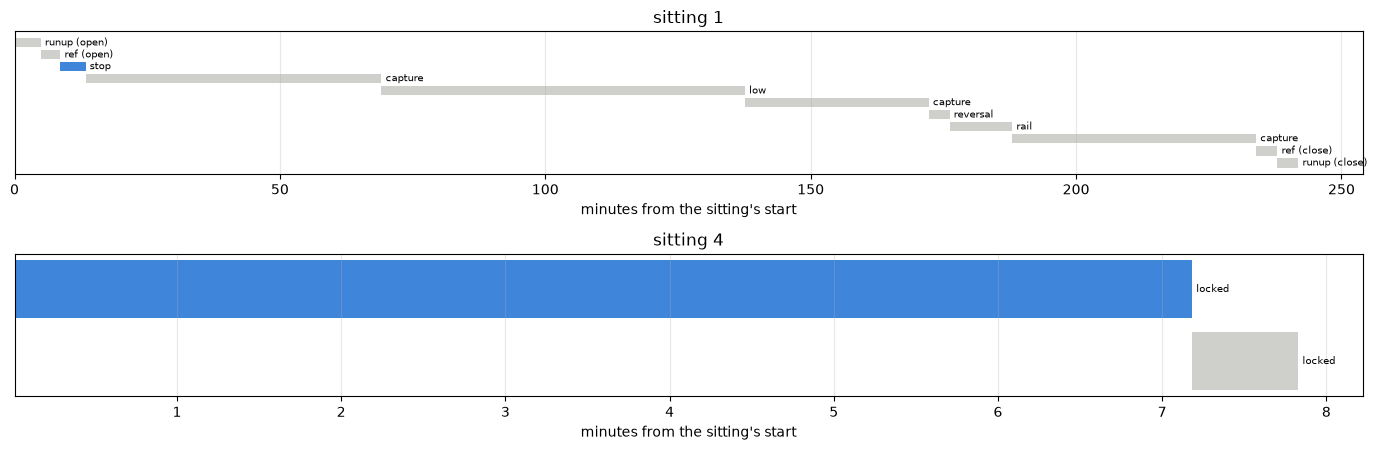

In [12]:
def plans(sitting):
    # each plan of a sitting with its start and end, minutes from the
    # sitting's first event, a plan ending where the next one starts
    m = manifest(sitting)
    t0 = m["t_host"].min()              # the sitting's first event
    p = m[m["event"] == "plan"][["t_host", "detail"]].copy()
    ends = list(p["t_host"].iloc[1:]) + [m["t_host"].max()]
    p["start_min"] = (p["t_host"] - t0) / 60
    p["end_min"] = (np.array(ends) - t0) / 60
    return p.rename(columns={"detail": "plan"}).reset_index(drop=True)


OURS = {1: "stop", 4: "locked"}         # the resistance plan per sitting
fig, ax = plt.subplots(2, 1, figsize=(14, 4.6))
for axis, sitting in zip(ax, (1, 4)):
    p = plans(sitting)
    ours = p.index[p["plan"] == OURS[sitting]][0]   # its first such plan
    for j, r in p.iterrows():
        mine = j == ours
        axis.barh(j, r["end_min"] - r["start_min"], left=r["start_min"],
                  color=BLUE if mine else MUTED, alpha=0.9 if mine else 0.4)
        axis.annotate(r["plan"], (r["end_min"], j), fontsize=7,
                      va="center", xytext=(3, 0), textcoords="offset points")
    axis.set_yticks([])
    axis.invert_yaxis()
    figures.label(axis, x="minutes from the sitting's start",
                  title=f"sitting {sitting}")
figures.finish(fig)

In [13]:
p1 = plans(1)
stop_at = p1[p1["plan"] == "stop"].iloc[0]
before = p1[p1["start_min"] < stop_at["start_min"]]
print(f"sitting 1: the stop plan starts {stop_at['start_min']:.1f} min in, "
      "after " + ", ".join(f"{r['plan']} ({r['start_min']:.1f} min)"
                           for _, r in before.iterrows()))
pilot = manifest(1).query("event == 'pilot'")["detail"].tolist()
print("the pilot before it:", pilot)
p4 = plans(4)
print("sitting 4: " + ", ".join(f"{r['plan']} at {r['start_min']:.1f} min"
                                for _, r in p4.iterrows()))
for name, ch in (("locked", CH_LOCKED), ("stop", CH_STOP)):
    m = manifest(SITTING[name])
    t0 = m["t_host"].min()
    print(f"{name}: sweeps from {(ch['t_start'].min() - t0) / 60:.1f} to "
          f"{(ch['t_end'].max() - t0) / 60:.1f} min into the sitting")

sitting 1: the stop plan starts 8.6 min in, after runup (open) (0.0 min), ref (open) (4.9 min)
the pilot before it: ['5.0 V 30 % for 300 ms: 3193 counts/s']
sitting 4: locked at 0.0 min, locked at 7.2 min
locked: sweeps from 0.0 to 6.8 min into the sitting
stop: sweeps from 8.6 to 13.1 min into the sitting


The stop chains ran 8.6 to 13.1 minutes into sitting 1, the servo's first. Before them only the 5 V 30 % pilot of 300 ms and the open run-up and reference plans had run on a motor whose brushes are new. In sitting 4 the locked laps ran first, and the inductance plan's bursts into the same lock followed them.

### One locked lap

The fourth locked sweep, chain 3 on 3.7 V, as recorded. The current, the two taps and the pot over the baseline and the two directions. Below it, what `meta.json` and the rows say.

segments: {0: 10000, 1: 6000, 2: 6000} | schedule: ['100@300'] | dirs: [1, -1] | rest ms: 20000 | rows dropped: 0
current limit 554 counts | rows carrying ntc_raw and vbus_raw: {'ntc_raw': 0, 'vbus_raw': 0}


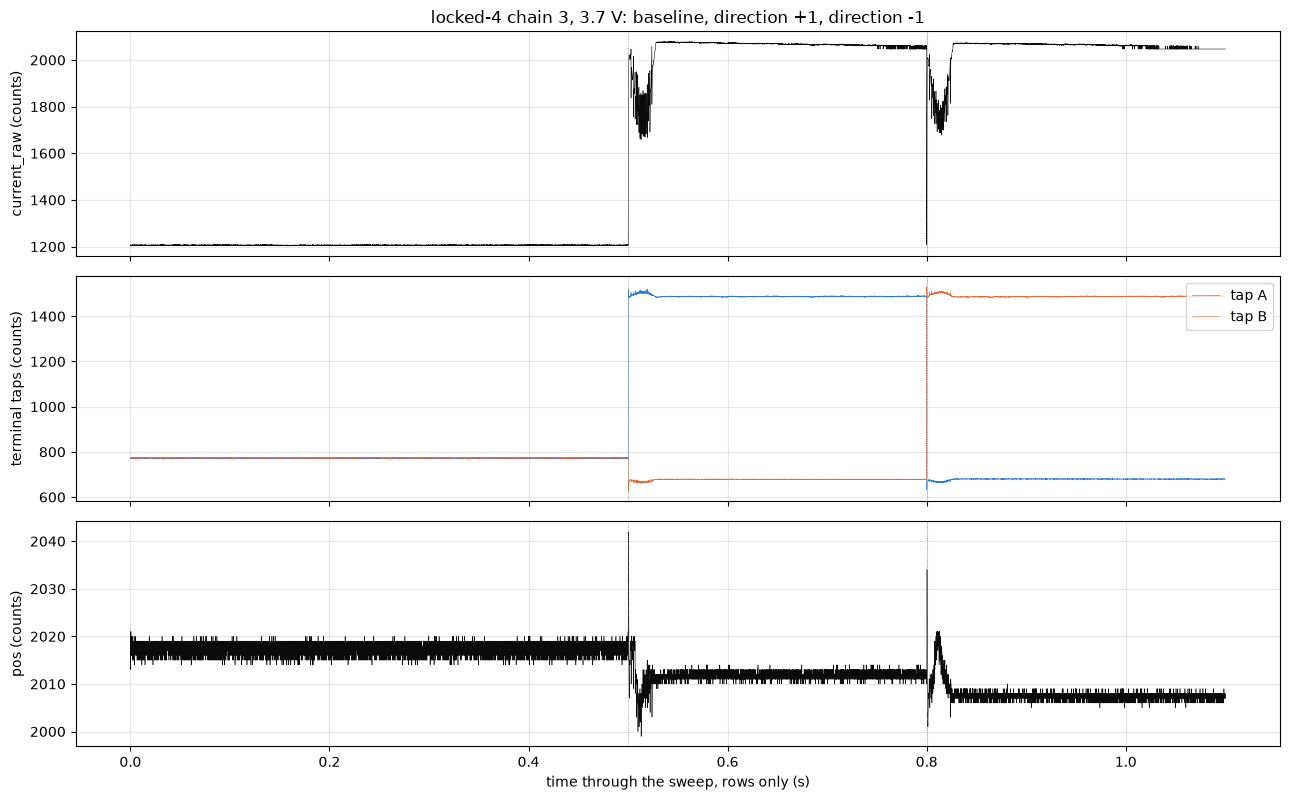

In [14]:
LAP_DF, LAP_META = tel.load(LOCKED / "chains" / "3", BOARD)   # checked
segs = LAP_DF["seg"].value_counts().sort_index().to_dict()
carried = {c: int(LAP_DF[c].notna().sum()) if c in LAP_DF else 0
           for c in ("ntc_raw", "vbus_raw")}
print("segments:", segs, "| schedule:", LAP_META["schedule"], "| dirs:",
      LAP_META["dirs"], "| rest ms:", LAP_META["rest_ms"],
      "| rows dropped:", LAP_META["rows_dropped"])
print("current limit", LAP_META["drive"]["current_limit_counts"],
      "counts | rows carrying ntc_raw and vbus_raw:", carried)
channels = [("current_raw (counts)", [(LAP_DF["current_raw"], INK)]),
            ("terminal taps (counts)", [(LAP_DF["vmotor_a"], BLUE, "tap A"),
                                        (LAP_DF["vmotor_b"], ORANGE,
                                         "tap B")]),
            ("pos (counts)", [(LAP_DF["pos"], INK)])]
fig, ax = figures.sweep_overview(
    LAP_DF, FS, channels,
    title="locked-4 chain 3, 3.7 V: baseline, direction +1, direction -1")
figures.finish(fig)

Half a second at the zero, then 300 ms each way. The 20 s rest between the two directions is not recorded, so the two streams sit end to end. The current channel reads the same current in both directions, since the shunt sits in the bridge's common return, and the taps swap. No row of the sweep carries `ntc_raw` or `vbus_raw`.

At the start of each direction the current rises to about 0.75 A, falls to about half of that within 15 ms and comes back. That dip is the rotor spinning free for a few turns before the lock takes the load, which the sections below read. The pot jumps by tens of counts at the same instant and is back within a couple of milliseconds, the same way in both directions. The horn moves at most a few counts against the lock, and a jump that fast and that large in both directions alike is a transient on the pot's reading at the current's step, not the seat.

### One stop chain

The first stop chain, chain 0 into the low stop, as recorded, with the applied duty in percent of the period.

segments: {0: 10000, 1: 6000, 2: 6000, 3: 6000} | schedule: ['24@300', 'then:36@300', 'then:24@300'] | stall: True | seek: 49 % | rows dropped: 0


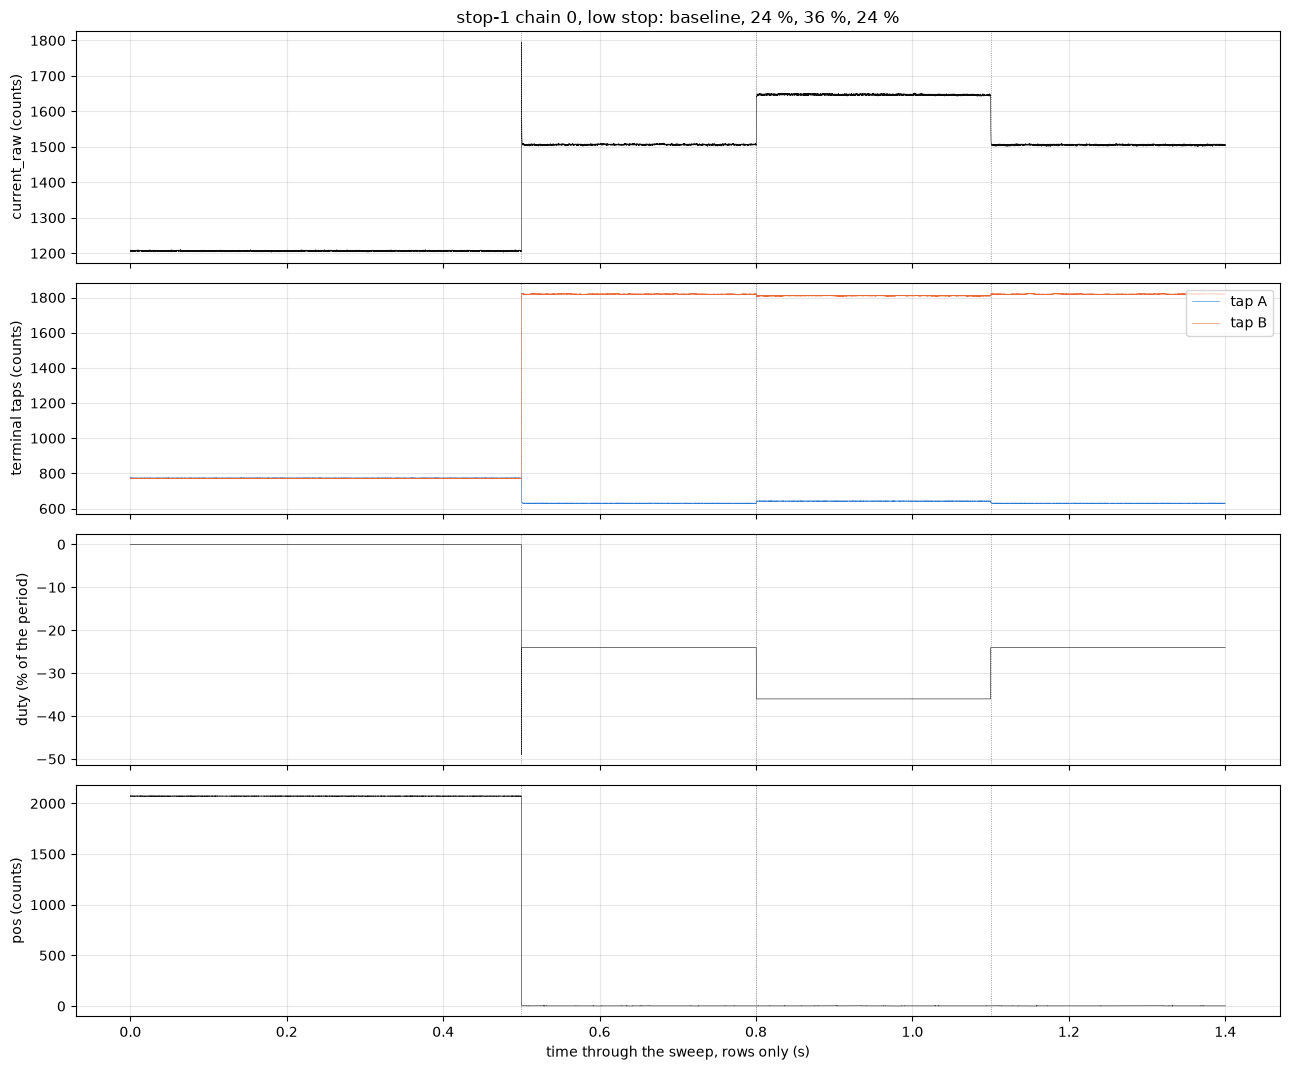

In [15]:
CHAIN_DF, CHAIN_META = tel.load(STOP / "chains" / "0", BOARD)
segs = CHAIN_DF["seg"].value_counts().sort_index().to_dict()
print("segments:", segs, "| schedule:", CHAIN_META["schedule"], "| stall:",
      CHAIN_META["stall"], "| seek:", CHAIN_META["seek_duty_pct"], "%",
      "| rows dropped:", CHAIN_META["rows_dropped"])
duty_pct = CHAIN_DF["duty_counts"] / ARR * 100      # signed, % of period
channels = [("current_raw (counts)", [(CHAIN_DF["current_raw"], INK)]),
            ("terminal taps (counts)",
             [(CHAIN_DF["vmotor_a"], BLUE, "tap A"),
              (CHAIN_DF["vmotor_b"], ORANGE, "tap B")]),
            ("duty (% of the period)", [(duty_pct, INK)]),
            ("pos (counts)", [(CHAIN_DF["pos"], INK)])]
fig, ax = figures.sweep_overview(
    CHAIN_DF, FS, channels,
    title="stop-1 chain 0, low stop: baseline, 24 %, 36 %, 24 %")
figures.finish(fig)

The baseline, then three segments of 300 ms at -24, -36 and -24 % with no release between them. Each segment opens with a few rows at the previous duty, the seek's 49 % before the first, and that is the stall press, not the step. The current settles within a millisecond at each step and stays flat. The pot reads 0 to 4 counts through the chain, at the bottom of its ADC range, 80 counts past the low end the servo's free stop reads with torque off. The stopper flexes under the press, and at the low end the pot's reading is on its rail and blind to the rotor.

## Method

### Conversions

The current over the sweep's own torque-off zero goes through the current-scale line, counts $= b + G_I\,I$, so

$$I = \frac{n - n_0 - b}{G_I}$$

with $n$ the current channel, $n_0$ the median of the second half of the sweep's baseline, $G_I$ the counts per amp and $b$ the in-drive offset. The terminal volts go through the terminal-chain line the same way,

$$V_\mathrm{on} = \frac{d\,(n_A - n_B) - c}{k_V}$$

with $n_A$ and $n_B$ the two taps, $d$ the direction, $k_V$ the counts per volt and $c$ its offset. The taps sit at the board's connector, so the reading carries the connector's contact and the servo's two motor leads on top of the motor. $V_\mathrm{on}$ is the crest sample's tap difference, the terminal volts while the bridge is on. The volts applied over a period are taken as

$$V_\mathrm{eff} = D\,V_\mathrm{on}$$

with $D$ ("D") the commanded duty, the window's ticks over 1200. At 100 % $D$ is 1 and $V_\mathrm{eff}$ is $V_\mathrm{on}$.

In [16]:
def boxcar(x, n=BOXCAR_ROWS):
    # the centered mean over n rows
    return np.convolve(x, np.ones(n) / n, mode="same")


def smooth_ratio(volts, amps):
    # V/I over the boxcar with its spoiled edges cut, and the rows kept
    keep = slice(EDGE_ROWS, len(volts) - EDGE_ROWS)
    return keep, (boxcar(volts) / boxcar(amps))[keep]


def held_rows(seg):
    # the rows of one segment at its held duty, the median of the
    # segment's second half, from the first row at that duty, so a seek
    # or the previous step's rows before it are out
    held = seg["duty_counts"].iloc[len(seg) // 2:].median()
    at = np.flatnonzero(seg["duty_counts"].to_numpy() == held)
    return seg.iloc[int(at[0]):], int(held), int(at[0])

In [17]:
def lap_signals(g, zero_i, direction, held):
    # current, crest volts and V_eff of one held stretch, row by row
    cur = g["current_raw"].to_numpy(float)          # counts
    taps = (g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * direction
    amps = SCALES.amps(cur, zero_i)     # over the zero, in-drive offset out
    v_on = SCALES.volts(taps, TAP_OFFSET)   # the crest tap difference
    duty = abs(held) / ARR              # the commanded duty, 1 at 100 %
    volts = duty * v_on                 # V_eff = D x V_on
    t = np.arange(len(g)) / FS          # s from the stretch's first row
    return {"cur": cur, "amps": amps, "v_on": v_on, "volts": volts,
            "duty": duty, "t": t, "pos": g["pos"].to_numpy(float)}

### Reading a lap

Stage 2's reading of a lap, unchanged. Each held stretch is read as a straight line through $V/I$ against time, from 60 ms after its first row to its end, extrapolated back to the first row. The value there, $R_\mathrm{start}$ ("R start"), is the path's resistance with the copper at the temperature it had when the lap began, and the line's slope is the warming rate. The current and the volts get lines of their own the same way, and their values at the first row are the points a line through the levels uses. The line's residual over 10 ms checks that the warming is straight. The settled mean from 2 ms, the early window 2 to 20 ms and the last 20 ms are read beside it for comparison.

In [18]:
def first_row_read(s):
    # V/I, I and V at the stretch's first row by lines over FIT_FROM_S
    # to the end, the V/I line's slope, its 10 ms residual, and the
    # current's scatter in counts over the same rows
    t, amps, volts = s["t"], s["amps"], s["volts"]
    late = t >= FIT_FROM_S
    ratio = volts / amps
    line = np.polyfit(t[late], ratio[late], 1)      # slope, first row
    resid = boxcar(ratio[late] - np.polyval(line, t[late]))
    resid_rms = np.sqrt(np.mean(resid[EDGE_ROWS:-EDGE_ROWS] ** 2))
    return {"r_first_ohm": line[1], "r_slope_ohm_per_s": line[0],
            "r_end_ohm": np.polyval(line, t[-1]),
            "i_first_a": np.polyfit(t[late], amps[late], 1)[1],
            "v_first_v": np.polyfit(t[late], volts[late], 1)[1],
            "resid_mohm": resid_rms * 1e3,
            "i_sd_counts": float(np.std(s["cur"][late]))}

In [19]:
def window_reads(s):
    # the plain means the line replaces, over their windows, for
    # comparison, and the lap's power and energy
    t, amps, volts = s["t"], s["amps"], s["volts"]
    early = (t >= EARLY_S[0]) & (t < EARLY_S[1])
    tail = t >= t[-1] - LATE_S
    settled = t >= SETTLED_FROM_S
    plateau = (t >= PLATEAU_S[0]) & (t < PLATEAU_S[1])
    power = volts * amps                # W, row by row
    return {"i_settled_a": amps[settled].mean(),
            "v_eff_settled_v": volts[settled].mean(),
            "v_on_settled_v": s["v_on"][settled].mean(),
            "r_settled_ohm": volts[settled].mean() / amps[settled].mean(),
            "r_early_ohm": volts[early].mean() / amps[early].mean(),
            "r_plateau_ohm": volts[plateau].mean() / amps[plateau].mean(),
            "r_tail_ohm": volts[tail].mean() / amps[tail].mean(),
            "watts": power[settled].mean(), "joules": power.sum() / FS,
            "lap_s": t[-1]}

### The plateau and the free spin

On a geared servo the early part of a locked lap carries something stage 2's bar on the pinion did not. The rotor turns through the train's play and the lock's give before the lock holds it, and while it turns its back-EMF takes current away. The read below finds the current's lowest point after its L/R rise, 1.5 ms, and before 30 ms, its fall under the plateau's mean from 30 to 60 ms, the EMF that fall implies at the plateau's $V_\mathrm{on}/I$, and when the current is back within 1 % of the plateau. Through this motor's $K_e$ the EMF is a speed. The plateau read, $V/I$ over 30 to 60 ms, sits after the spin and before most of the warming, a check on the first-row read beside it.

In [20]:
def free_spin(s):
    # the current's dip under its plateau after the L/R rise, the EMF the
    # dip implies at the plateau's V_on / I, and when the current is back
    # within BACK_SHARE of the plateau
    t, amps, v_on = s["t"], s["amps"], s["v_on"]
    plateau = (t >= PLATEAU_S[0]) & (t < PLATEAU_S[1])
    i_plateau = amps[plateau].mean()    # A, the level the dip falls from
    from_k = int(DIP_FROM_S * FS)       # row, past the L/R rise
    dip_k = from_k + int(np.argmin(amps[from_k:int(PLATEAU_S[0] * FS)]))
    back = np.flatnonzero((t > t[dip_k])
                          & (amps >= BACK_SHARE * i_plateau))
    until_s = float(t[back[0]]) if len(back) else np.nan
    r_on = v_on[plateau].mean() / i_plateau     # ohm, V_on / I there
    emf = float(v_on[dip_k] - r_on * amps[dip_k])   # V at the dip
    return {"i_plateau_a": i_plateau, "i_dip_a": float(amps[dip_k]),
            "t_dip_ms": float(t[dip_k] * 1e3), "emf_dip_v": emf,
            "spin_until_ms": until_s * 1e3}

In [21]:
def read_step(g, zero_i, direction, held, first_row):
    # every read of one held stretch, its signals kept for the figures
    s = lap_signals(g, zero_i, direction, held)
    settled = s["t"] >= SETTLED_FROM_S
    pos = s["pos"]
    return {"dir": direction, "duty_pct": s["duty"] * 100,
            "held_ticks": held, "rows_before_held": first_row,
            "rows": len(g), **first_row_read(s), **window_reads(s),
            **free_spin(s), "pos_median": float(np.median(pos[settled])),
            "pos_min": float(pos.min()), "pos_max": float(pos.max()),
            "pos_first": float(pos[0]),
            "pos_last": float(np.median(pos[-LAST_ROWS:])), "trace": s}

In [22]:
def sweep_steps(folder):
    # every driven segment of one sweep read as a step over the sweep's
    # own zero, with its seek rows and the baseline's pos
    df, meta = tel.load(folder, BOARD)  # checks the sense block
    zero_i, _ = tel.rest_zeros(df)      # the torque-off zero
    rest = tel.baseline(df)             # the baseline's rows
    missing = int(tel.gaps(df).sum())   # dropped rows, from tick
    out = []
    for seg, g in df[df["seg"] > 0].groupby("seg"):
        direction = int(g["dir"].iloc[0])
        g_held, held, first_row = held_rows(g)
        step = read_step(g_held, zero_i, direction, held, first_row)
        seek = g.iloc[:first_row]       # rows before the held duty
        seek_i = (float(SCALES.amps(seek["current_raw"].to_numpy(float),
                                    zero_i).mean()) if first_row else np.nan)
        step.update({"seg": int(seg), "zero_counts": float(zero_i),
                     "missing": missing,
                     "pos_rest": float(rest["pos"].median()),
                     "seek_rows": first_row, "seek_i_a": seek_i,
                     "seek_ticks": int(seek["duty_counts"].abs().max())
                     if first_row else 0})
        out.append(step)
    return out

### Which laps carry the number

$R_\mathrm{term}$ is the first-row read on the six 3.7 V laps, both directions, their mean with the range as the bounds. Stage 2's direction -1 lap ran a second after direction +1 and started warm, so stage 2 carried direction +1 alone. Here the two directions run 20 s apart and the copper, with a time constant near 2 s on the type, has cooled, so both carry the number and the directions are reported beside it. The 3.3 V laps sit off stage 1's graded lines and enter no number but the two-level line, which is report-only.

### The two-level line and its lever

The line $V = V_0 + R\,I$ through the first-row points of the two levels gives $R$ and $V_0$, in the form

$$\frac{V}{I} = R + \frac{V_0}{I},$$

so on a plot of $V/I$ against $1/I$ the slope is $V_0$ and the intercept $R$. The lever is how far $1/I$ moves between the levels. A change of 0.1 % in $V/I$ between them moves $V_0$ by $0.001\,R / \Delta(1/I)$, and that number says whether a pair of levels can hold a $V_0$ at all. The line is drawn twice, with the 3.3 V volts as read and over the stage 1 factor.

### The stop chain's construction

A stop step is read with the same functions, from its first row at the held duty, as $V_\mathrm{eff} / I_\mathrm{crest}$, the plain construction the sag notebook used, formed from the commanded duty, the crest tap difference and the crest current, the three things a pass on the board's own readings has. The rotor is pressed into its stop, so no spin opens a step. Per chain the two 24 % steps are averaged against the 36 % step, and $R$ and $V_0$ are the line through those two points. A warming that is linear through the chain cancels in the average, since the two 24 % steps sit either side of the 36 % one. The least squares line through all eighteen points is the check.

In [23]:
def chain_lines(t, i_col, v_col, label):
    # V = V0 + R I per chain: least squares through its three steps, and
    # through two points, the two 24 % steps averaged against the 36 %
    out = []
    for k, g in t.groupby("chain"):
        g = g.sort_values("step")
        f = laps.line(g[i_col], g[v_col])
        low = g[g["step"] != 2]                 # the two 24 % steps
        high = g[g["step"] == 2].iloc[0]        # the 36 % step
        i_lo, v_lo = low[i_col].mean(), low[v_col].mean()
        r2 = (high[v_col] - v_lo) / (high[i_col] - i_lo)
        s1 = g[g["step"] == 1].iloc[0]
        s3 = g[g["step"] == 3].iloc[0]
        warm = ((s3[v_col] / s3[i_col]) / (s1[v_col] / s1[i_col]) - 1) * 100
        out.append({"read": label, "chain": k, "stop": g["stop"].iloc[0],
                    "dir": g["dir"].iloc[0], "r_ls_ohm": f["slope"],
                    "r_ls_se": f["slope_se"], "v0_ls_v": f["intercept"],
                    "v0_ls_se": f["intercept_se"], "rms_mv": f["rms"] * 1e3,
                    "r_bracket_ohm": r2, "v0_bracket_v": v_lo - r2 * i_lo,
                    "step3_over_step1_pct": warm, "i_lo_a": i_lo,
                    "i_hi_a": high[i_col],
                    "lever_per_a": 1 / i_lo - 1 / high[i_col]})
    return pd.DataFrame(out)

### What stage 1 says the construction leaves out

$V_\mathrm{eff} = D\,V_\mathrm{on}$ over the crest current takes the commanded window as the applied one and the motor's volts between windows as zero. Stage 1 measured two board terms that say otherwise, both shown in the stage 1 values above.

- The edge lags. The tap's ON edge comes later after the commanded start than the OFF edge after the commanded end, so the applied window is `EDGE` ticks of the 2400 tick period shorter than $D$ says. The effective duty is $D' = (2 D \cdot 1200 - \mathrm{EDGE}) / 2400$ ("D prime").
- The brake drop. Between windows the bridge shorts the winding through its low side, and the terminals read the circulating current's drop across the low-side loop, $-R_\mathrm{loop}\,i$ ("R loop"). The period's mean volts are then $D' V_\mathrm{on} - (1 - D')\,R_\mathrm{loop}\,i$.

Both make the as-read $V/I$ high at partial duty and vanish at 100 %. A third term is the crest's over-read of the period's mean current, which stage 2 modeled as $G\,(1 - D)\,V_\mathrm{on}$, the held-stall form the inductance notebook used, or a constant offset. The function below builds the applied volts and the winding current under any mix of the three. With every term zero it gives the as-read construction.

In [24]:
def construct(d_cmd, v_on, i_crest, edge_ticks=0.0, loop_ohm=0.0,
              g_s=0.0, offset_a=0.0):
    # the applied volts and the winding current a construction gives
    # from the commanded duty D, the crest tap difference V_on and the
    # crest current: the window shortened by edge_ticks of the 2 x ARR
    # period, the brake interval's drop loop_ohm x i over the rest of
    # the period, the crest over the mean by g_s x (1 - D) V_on plus a
    # constant offset
    d_eff = (2 * d_cmd * ARR - edge_ticks) / (2 * ARR)
    i_mean = i_crest - g_s * (1 - d_cmd) * v_on - offset_a
    v = d_eff * v_on - (1 - d_eff) * loop_ohm * i_mean
    return v, i_mean

### Error bars

$R_\mathrm{term}$'s bounds are the range over the six laps, and its scatter the standard deviation over them. A stop line's bounds are one standard deviation over the six chains, and the pooled line's are its standard error. The constructions carry stage 1's bounds on the edge lags and the loop as separate rows, not as one error bar. A slope that a construction predicts is graded against the sag's measured slope in units of the sag's standard error, $\sigma$ ("sigma"). Nothing under $2\,\sigma$ is called a finding. The commutator's angle moves every terminal reading by a few percent on the type, and one seat per route here does not measure it.

## The locked laps

Every lap of the six locked sweeps through the reading above, one row per lap, with the board NTC from the probes around its sweep.

In [25]:
rows, TRACES = [], {}           # one row per lap, its signals by key
for _, c in CH_LOCKED.iterrows():
    k = int(c["k"])
    board_c = ntc_around(PROBES_LOCKED, c["t_start"], c["t_end"])[0]
    for s in sweep_steps(LOCKED / c["folder"]):
        TRACES[(k, s["dir"])] = s.pop("trace")
        rows.append({"chain": k, "volts_set": c["volts_set"],
                     "graded": c["volts_set"] >= RAIL_GRADED_V,
                     "pos_before": c["pos_before"],
                     "pos_after": c["pos_after"], "board_c": board_c, **s})
L = pd.DataFrame(rows)
first = L["r_first_ohm"]
L["rise_pct_per_s"] = L["r_slope_ohm_per_s"] / first * 100
L["pct_per_j"] = L["rise_pct_per_s"] / L["watts"]       # % per J
L["early_pct"] = (L["r_early_ohm"] / first - 1) * 100
L["settled_over_first_pct"] = (L["r_settled_ohm"] / first - 1) * 100
L["plateau_over_first_pct"] = (L["r_plateau_ohm"] / first - 1) * 100
L["dip_pct"] = (L["i_dip_a"] / L["i_plateau_a"] - 1) * 100
L["emf_dip_rev_s"] = L["emf_dip_v"] / KE     # the dip's EMF as a speed
L["pos_lap_shift"] = L["pos_after"] - L["pos_before"]
print(f"{len(L)} laps, {int(L['missing'].max())} rows missing in any "
      f"sweep, {L['rows_before_held'].min()} to "
      f"{L['rows_before_held'].max()} rows before the drive")

12 laps, 0 rows missing in any sweep, 0 to 8 rows before the drive


In [26]:
show(L[["chain", "volts_set", "dir", "i_first_a", "v_on_settled_v",
        "r_first_ohm", "r_plateau_ohm", "r_settled_ohm",
        "rise_pct_per_s", "watts", "joules", "pct_per_j", "resid_mohm",
        "i_sd_counts", "board_c", "pos_before", "pos_after"]].round(4),
     n=None)
settled = L["settled_over_first_pct"].mean()   # %, mean over the laps
print(f"settled mean over the first row {settled:+.2f} %, early window "
      f"{L['early_pct'].min():+.1f} to "
      f"{L['early_pct'].max():+.1f} %; line residual "
      f"{L['resid_mohm'].median():.1f} mohm median, "
      f"{L['resid_mohm'].max():.1f} at most")

,chain,volts_set,dir,i_first_a,v_on_settled_v,r_first_ohm,r_plateau_ohm,r_settled_ohm,rise_pct_per_s,watts,joules,pct_per_j,resid_mohm,i_sd_counts,board_c,pos_before,pos_after
0,0,3.300,1,0.741,3.209,4.322,4.338,4.499,7.447,2.288,0.685,3.255,1.964,4.225,26.096,2015,2015
1,0,3.300,-1,0.738,3.201,4.331,4.348,4.487,7.116,2.283,0.683,3.117,2.149,4.039,26.096,2015,2015
2,1,3.300,1,0.739,3.209,4.333,4.344,4.497,7.078,2.289,0.685,3.093,2.733,4.022,26.199,2015,2020
3,1,3.300,-1,0.736,3.202,4.341,4.347,4.496,6.548,2.279,0.682,2.874,1.563,3.706,26.199,2015,2020
4,2,3.300,1,0.739,3.210,4.335,4.351,4.501,7.400,2.288,0.686,3.235,2.017,4.157,26.236,2019,2019
5,2,3.300,-1,0.737,3.202,4.337,4.337,4.497,7.096,2.278,0.682,3.115,2.304,4.003,26.236,2019,2019
6,3,3.700,1,0.767,3.253,4.227,4.257,4.408,10.769,2.399,0.719,4.489,5.698,6.471,26.280,2020,2015
7,3,3.700,-1,0.767,3.247,4.212,4.269,4.422,15.960,2.383,0.714,6.697,12.728,8.978,26.280,2020,2015
8,4,3.700,1,0.766,3.255,4.230,4.251,4.396,9.554,2.409,0.722,3.966,2.236,5.103,26.317,2018,2018
9,4,3.700,-1,0.767,3.240,4.207,4.201,4.343,9.230,2.416,0.724,3.821,1.144,4.985,26.317,2018,2018


settled mean over the first row +4.01 %, early window +35.9 to +53.5 %; line residual 2.3 mohm median, 13.7 at most


One row per lap. At 3.7 V the first-row read is 4.207 to 4.230 ohm at 0.765 to 0.768 A, and at 3.3 V 4.322 to 4.341 ohm at 0.736 to 0.741 A. Each lap put 0.68 to 0.72 J into the motor at 2.3 to 2.4 W. The settled mean from 2 ms reads 4.0 % over the first row on average, and the early window 36 to 54 % over it, since both hold the free spin the next figure shows. The line leaves 2.3 mohm in the median over 10 ms and 13.7 mohm at most, on chain 5's -1 lap. No row is missing from any sweep.

In [27]:
def lap_panel(ax):
    # every lap's V/I through the lap, its line dotted back to its first
    # row, the stretch the line leaves out and the plateau shaded
    for _, r in L.iterrows():
        s = TRACES[(int(r["chain"]), int(r["dir"]))]
        keep, ratio = smooth_ratio(s["volts"], s["amps"])
        color = COLOR[r["volts_set"]]
        named = int(r["chain"]) in (0, 3)       # one legend entry a level
        ax.plot(s["t"][keep] * 1e3, ratio, lw=0.8, color=color,
                ls="-" if r["dir"] == 1 else "--",
                label=(f"{r['volts_set']:g} V, direction {int(r['dir']):+d}"
                       if named else None))
        ends = np.array([0, s["t"][-1]])        # s, the lap's two ends
        ax.plot(ends * 1e3, r["r_first_ohm"] + r["r_slope_ohm_per_s"] * ends,
                lw=0.6, color=INK, ls=":")
        ax.plot(0, r["r_first_ohm"], "o", ms=4, color=color)
    ax.axvspan(0, FIT_FROM_S * 1e3, color=MUTED, alpha=0.12,
               label="left out of the line")
    ax.axvspan(PLATEAU_S[0] * 1e3, PLATEAU_S[1] * 1e3, color=GREEN,
               alpha=0.10, label="the plateau read")
    ax.set_ylim(4.1, 4.6)
    ax.legend(fontsize=7, ncol=2)
    figures.label(ax, x="ms from the drive's first row",
                  y="V/I, 10 ms boxcar (ohm)",
                  title="the twelve locked laps")

The twelve laps' $V/I$ through the lap on the left, each lap's line dotted back to its first-row value, the 60 ms the line leaves out shaded gray and the plateau window green. In the middle and on the right, the current and the pot of chain 3's two laps over their first 40 ms. The thing to see is where the line starts against the free spin, and what the pot does at the step.

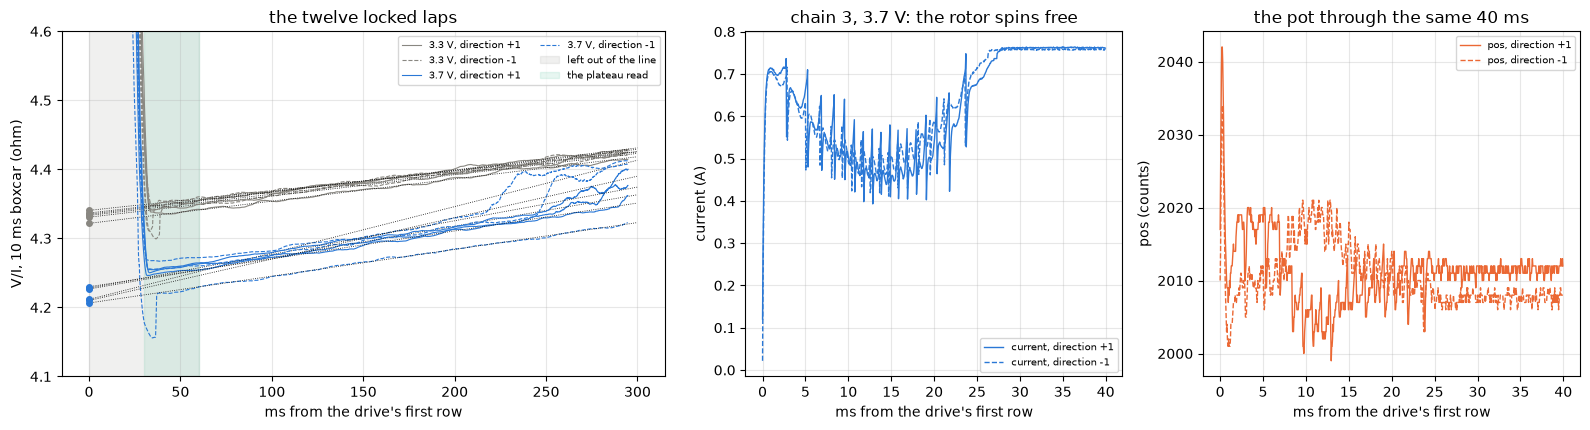

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4),
                       gridspec_kw={"width_ratios": [1.6, 1, 1]})
lap_panel(ax[0])
for d, ls in ((1, "-"), (-1, "--")):
    s = TRACES[(3, d)]
    m = s["t"] < 0.040                  # the first 40 ms
    ax[1].plot(s["t"][m] * 1e3, s["amps"][m], ls, lw=1, color=BLUE,
               label=f"current, direction {d:+d}")
    ax[2].plot(s["t"][m] * 1e3, s["pos"][m], ls, lw=1, color=ORANGE,
               label=f"pos, direction {d:+d}")
figures.label(ax[1], x="ms from the drive's first row", y="current (A)",
              title="chain 3, 3.7 V: the rotor spins free")
figures.label(ax[2], x="ms from the drive's first row", y="pos (counts)",
              title="the pot through the same 40 ms")
for a in ax[1:]:
    a.legend(fontsize=7)
figures.finish(fig)

In [29]:
print(f"dip {L['dip_pct'].mean():.0f} % under the plateau "
      f"({L['dip_pct'].min():.0f} to {L['dip_pct'].max():.0f}) at "
      f"{L['t_dip_ms'].min():.0f} to {L['t_dip_ms'].max():.0f} ms; EMF "
      f"{L['emf_dip_v'].min():.2f} to {L['emf_dip_v'].max():.2f} V, "
      f"{L['emf_dip_rev_s'].min():.0f} to {L['emf_dip_rev_s'].max():.0f} "
      f"rev/s (mean {L['emf_dip_rev_s'].mean():.0f}); back on the plateau by "
      f"{L['spin_until_ms'].min():.1f} to {L['spin_until_ms'].max():.1f} ms "
      f"(mean {L['spin_until_ms'].mean():.1f})")
jump, at_ms, after = [], [], []         # the pot at the step, and after
for (k, d), s in TRACES.items():
    rest = L[(L["chain"] == k) & (L["dir"] == d)]["pos_rest"].iloc[0]
    early = s["t"] < SETTLED_FROM_S     # the first 2 ms
    over = s["pos"][early] - rest       # counts over the baseline's pos
    jump.append(over.max())
    at_ms.append(s["t"][early][np.argmax(over)] * 1e3)
    after.append(np.median(s["pos"][~early]) - rest)
print(f"pot over the baseline in the first 2 ms: {min(jump):.0f} to "
      f"{max(jump):.0f} counts at {min(at_ms):.2f} to {max(at_ms):.2f} ms; "
      f"its median from 2 ms on {min(after):+.0f} to {max(after):+.0f} "
      "counts from the baseline")

dip -49 % under the plateau (-58 to -45) at 10 to 17 ms; EMF 1.61 to 2.02 V, 220 to 276 rev/s (mean 237); back on the plateau by 22.5 to 28.9 ms (mean 27.1)
pot over the baseline in the first 2 ms: 16 to 72 counts at 0.20 to 0.35 ms; its median from 2 ms on -11 to -3 counts from the baseline


After the L/R rise the current reaches about 0.7 A within a millisecond, then falls to a low point 45 to 58 % under the plateau, 49 % on average, at 10 to 17 ms, and is back within 1 % of the plateau by 22.5 to 28.9 ms in every lap. At the plateau's $V_\mathrm{on}/I$ the low point is an EMF of 1.61 to 2.02 V, 220 to 276 rev/s at this motor's $K_e$. The rotor runs through the train's play and the lock's give before the lock holds it, with high confidence, since all twelve laps show the same shape in both directions. Stage 2's bar on the pinion left an early fall of about 1 % over 30 to 50 ms. Here it is a dip of half the current over 25 ms. The line from 60 ms clears it by about 30 ms. The early window and the settled mean both hold it, so on a geared servo neither is a number.

The pot reads 16 to 72 counts over its baseline 0.20 to 0.35 ms into each lap and is back within a couple of milliseconds. Through the spin it wanders by about ten counts, and from 2 ms on its median sits 3 to 11 counts under the baseline. A jump that fast and that large, the same way in both directions, is a transient on the pot's reading at the current's step and not the seat, likely.

### $R_\mathrm{term}$

The headline read, the six 3.7 V laps' first-row values.

In [30]:
G3 = L[L["graded"]]                     # the six 3.7 V laps
LOW = L[~L["graded"]]                   # the six 3.3 V laps
R_TERM = G3["r_first_ohm"].mean()       # ohm, the headline
R_TERM_SD = G3["r_first_ohm"].std()     # ohm, over the six laps
I_TERM = G3["i_first_a"].mean()         # A, its current
T_ROOM = L["board_c"].median()          # C, the board NTC, the room's
R_DIR = G3.groupby("dir")["r_first_ohm"]
print(f"R_term (3.7 V, both directions, 6 laps): {R_TERM:.4f} ohm sd "
      f"{R_TERM_SD:.4f} ({R_TERM_SD / R_TERM * 100:.2f} %) at {I_TERM:.4f}"
      f" A, {G3['r_first_ohm'].min():.4f} to {G3['r_first_ohm'].max():.4f}")
print("by direction: " + ", ".join(
    f"{d:+d} {g.mean():.4f} sd {g.std():.4f}" for d, g in R_DIR))
print(f"median over the six laps {G3['r_first_ohm'].median():.4f} ohm; the "
      f"inductance anchor {R_ANCHOR['value']:.4f}")
print(f"board NTC median {T_ROOM:.2f} C ({L['board_c'].min():.2f} to "
      f"{L['board_c'].max():.2f})")

R_term (3.7 V, both directions, 6 laps): 4.2189 ohm sd 0.0105 (0.25 %) at 0.7666 A, 4.2065 to 4.2300
by direction: -1 4.2094 sd 0.0027, +1 4.2283 sd 0.0017
median over the six laps 4.2192 ohm; the inductance anchor 4.2189
board NTC median 26.26 C (26.10 to 26.32)


The six 3.7 V laps read $R_\mathrm{term}$ = 4.2189 ohm, sd 0.0105 (0.25 %), at 0.7666 A, from 4.2065 to 4.2300. Direction +1 reads 4.2283 and direction -1 4.2094, and the median of the six is 4.2192. The inductance notebook read the same laps for its anchor and got 4.2189, which this read confirms. This is $V/I$ at 0.767 A with $V_0$ inside it, stage 2's definition of $R_\mathrm{term}$, and no construction enters it. The board's NTC read 26.10 to 26.32 C through the plan.

### The two directions

Direction -1's first-row read over direction +1's, per sweep. The -1 lap runs 20 s after the +1 lap.

In [31]:
GAPS = L.pivot(index=["chain", "volts_set"], columns="dir",
               values="r_first_ohm")
GAPS["gap_pct"] = (GAPS[-1] / GAPS[1] - 1) * 100    # -1 over +1, 20 s on
show(GAPS.round(4).reset_index(), n=None)
for v, g in GAPS.groupby(level="volts_set"):
    print(f"{v} V: direction -1 over +1 {g['gap_pct'].mean():+.2f} % "
          f"({g['gap_pct'].min():+.2f} to {g['gap_pct'].max():+.2f})")
gap3 = GAPS.xs(3.7, level="volts_set")["gap_pct"]
sd_each = G3.groupby("dir")["r_first_ohm"].std() / R_TERM * 100
print(f"3.7 V gap {gap3.mean():+.2f} % against each direction's sd "
      f"{sd_each.min():.2f} to {sd_each.max():.2f} % over three laps; the "
      f"gap over its own standard error "
      f"{gap3.mean() / (gap3.std() / np.sqrt(len(gap3))):+.1f}")

dir,chain,volts_set,-1,1,gap_pct
0,0,3.300,4.331,4.322,0.207
1,1,3.300,4.341,4.333,0.168
2,2,3.300,4.337,4.335,0.043
3,3,3.700,4.212,4.227,-0.356
4,4,3.700,4.207,4.230,-0.557
5,5,3.700,4.210,4.228,-0.427


3.3 V: direction -1 over +1 +0.14 % (+0.04 to +0.21)
3.7 V: direction -1 over +1 -0.45 % (-0.56 to -0.36)
3.7 V gap -0.45 % against each direction's sd 0.04 to 0.06 % over three laps; the gap over its own standard error -7.6


At 3.7 V direction -1 reads 0.36 to 0.56 % under direction +1, -0.45 % on average. At 3.3 V it reads 0.04 to 0.21 % over it. Stage 2 had direction -1 1.19 % over +1 a second after it and read that as heat carried from the first lap. With 20 s between them here the copper's heat is gone, and at 3.7 V the sign has turned. Within each direction the three 3.7 V laps scatter by 0.04 to 0.06 %, so the gap is several times the laps' own scatter. Direction and order go together, since the -1 lap always runs second. The 3.7 V -1 laps are also among the noisiest and steepest, the next section shows. Creep that differs by sign is the first candidate, and a direction term at the brushes the second. $R_\mathrm{term}$ is carried over both directions with the two beside it.

### The quiet gate and the plateau

The plant traps set a gate for a quiet locked rotor, a current sd of 4.5 counts or less. Below, each lap over the plateau and over the line's 60 to 300 ms, with the pot's range and the largest change of the 10 ms $V/I$ over 10 ms.

In [32]:
def quiet(s, lo, hi):
    # the quiet-rotor gate over [lo, hi) s: the current's sd in counts,
    # the pot's range, and the largest change of the 10 ms V/I over 10 ms
    m = (s["t"] >= lo) & (s["t"] < hi)
    counts = s["amps"] * SCALES.counts_per_a    # counts over the zero
    ratio = boxcar(s["volts"])[m] / boxcar(s["amps"])[m]
    step = (np.max(np.abs(ratio[STEP_ROWS:] - ratio[:-STEP_ROWS]))
            / ratio.mean() * 100 if m.sum() > 2 * STEP_ROWS else np.nan)
    return {"i_sd_counts": counts[m].std(),
            "pos_range": s["pos"][m].max() - s["pos"][m].min(),
            "max_10ms_step_pct": step}


QL = pd.DataFrame([{"chain": k, "level": L[L["chain"] == k][
                        "volts_set"].iloc[0], "dir": d, "window": name,
                    **quiet(s, lo, hi)}
                   for (k, d), s in TRACES.items()
                   for name, lo, hi in (("plateau 30-60", *PLATEAU_S),
                                        ("line 60-300", FIT_FROM_S, 0.3))])
QL["over_gate"] = QL["i_sd_counts"] > QUIET_SD_COUNTS
show(QL.round(3), n=None)

,chain,level,dir,window,i_sd_counts,pos_range,max_10ms_step_pct,over_gate
0,0,3.300,1,plateau 30-60,1.207,4.000,4.471,False
1,0,3.300,1,line 60-300,4.225,5.000,0.222,False
2,0,3.300,-1,plateau 30-60,1.453,4.000,2.403,False
3,0,3.300,-1,line 60-300,4.039,5.000,0.200,False
4,1,3.300,1,plateau 30-60,1.246,4.000,2.648,False
5,1,3.300,1,line 60-300,4.022,6.000,0.276,False
6,1,3.300,-1,plateau 30-60,5.057,9.000,1.001,True
7,1,3.300,-1,line 60-300,3.706,5.000,0.175,False
8,2,3.300,1,plateau 30-60,1.244,4.000,2.972,False
9,2,3.300,1,line 60-300,4.157,5.000,0.215,False


In [33]:
for (window, level), g in QL.groupby(["window", "level"]):
    over = g[g["over_gate"]]
    print(f"{window}, {level} V: current sd {g['i_sd_counts'].min():.2f} "
          f"to {g['i_sd_counts'].max():.2f} counts, largest 10 ms step "
          f"{g['max_10ms_step_pct'].max():.3f} %; over the "
          f"{QUIET_SD_COUNTS} gate: " + (", ".join(
              f"chain {int(r['chain'])} {int(r['dir']):+d}"
              for _, r in over.iterrows()) or "none"))
copper_rate = (RR_B["warming_pct_per_j"]["value"] / 100
               * G3["watts"].mean())   # per s, the type's at this power
R_PLATEAU = G3["r_plateau_ohm"].mean()
R_PLATEAU_COLD = R_PLATEAU / (1 + copper_rate * PLATEAU_MID_S)
print(f"plateau read (3.7 V, 6 laps): {R_PLATEAU:.4f} ohm sd "
      f"{G3['r_plateau_ohm'].std():.4f} ({G3['r_plateau_ohm'].min():.4f} "
      f"to {G3['r_plateau_ohm'].max():.4f}); less the type's copper "
      f"warming to {PLATEAU_MID_S * 1e3:.0f} ms: {R_PLATEAU_COLD:.4f}, "
      f"{(R_PLATEAU_COLD / R_TERM - 1) * 100:+.2f} % on R_term")

line 60-300, 3.3 V: current sd 3.71 to 4.23 counts, largest 10 ms step 0.276 %; over the 4.5 gate: none
line 60-300, 3.7 V: current sd 4.98 to 8.98 counts, largest 10 ms step 1.247 %; over the 4.5 gate: chain 3 +1, chain 3 -1, chain 4 +1, chain 4 -1, chain 5 +1, chain 5 -1
plateau 30-60, 3.3 V: current sd 1.21 to 16.71 counts, largest 10 ms step 4.471 %; over the 4.5 gate: chain 1 -1, chain 2 -1
plateau 30-60, 3.7 V: current sd 0.98 to 28.26 counts, largest 10 ms step 1.749 %; over the 4.5 gate: chain 4 -1
plateau read (3.7 V, 6 laps): 4.2491 ohm sd 0.0244 (4.2008 to 4.2695); less the type's copper warming to 45 ms: 4.2360, +0.41 % on R_term


In [34]:
rows = []                       # the lowest 10 ms V/I on the plateau
for (k, d), s in TRACES.items():
    keep, ratio = smooth_ratio(s["volts"], s["amps"])
    t = s["t"][keep]
    m = (t >= PLATEAU_S[0]) & (t < PLATEAU_S[1])
    j = int(np.argmin(ratio[m]))
    rows.append({"chain": k, "dir": d, "low_ohm": ratio[m][j],
                 "at_ms": t[m][j] * 1e3})
DIPS = pd.DataFrame(rows).sort_values("low_ohm")
show(DIPS.head(3).round(3), n=None)

,chain,dir,low_ohm,at_ms
9,4,-1,4.156,34.750
8,4,1,4.246,32.850
6,3,1,4.250,33.200


Over the line's 60 to 300 ms every 3.7 V lap is over the gate, at 4.98 to 8.98 counts, and every 3.3 V lap under it, at 3.71 to 4.23. The 3.7 V traces also carry steps of up to 1.25 % in 10 ms, against 0.28 % at most at 3.3 V. On the plateau three laps are over the gate, chain 4's -1 lap at 3.7 V at 28 counts and chain 2's and chain 1's -1 laps at 3.3 V at 17 and 5 counts. Chain 4's -1 lap dips to 4.156 ohm at 35 ms inside the plateau window, the dashed blue trace under the others in the figure above.

The plateau read over the six 3.7 V laps is 4.2491 ohm, sd 0.0244, from 4.2008 to 4.2695, a spread more than twice the first-row read's. Less the type's copper warming to the window's middle, 45 ms, it is 4.2360, 0.41 % over the extrapolated 4.2189. So the choice between the plateau and the first row is worth about 0.4 %, and the plateau stays a secondary check beside the first-row read.

### The warming

Each lap's line slope per watt against the type's.

In [35]:
PCT_PER_J = G3["pct_per_j"].mean()      # % per J, the 3.7 V laps
ALPHA_CU = 1 / (COPPER_ZERO_C + T_ROOM)  # per C, copper at the room
C_MAX = ALPHA_CU * 100 / PCT_PER_J      # J/C, all copper, no heat lost
print(f"warming: 3.7 V laps {PCT_PER_J:.2f} % per J "
      f"({G3['pct_per_j'].min():.2f} to {G3['pct_per_j'].max():.2f}), "
      f"{G3['rise_pct_per_s'].min():.1f} to {G3['rise_pct_per_s'].max():.1f}"
      f" %/s at {G3['watts'].mean():.2f} W; 3.3 V laps "
      f"{LOW['pct_per_j'].mean():.2f} % per J at {LOW['watts'].mean():.2f} W")
print(f"type: mg90-b {RR_B['warming_pct_per_j']['value']:.2f}, mg90-c "
      f"{RR_C['warming_pct_per_j']['value']:.2f} % per J")
print(f"if every ohm were copper keeping all its heat: at most "
      f"{C_MAX:.3f} J/C, {C_MAX / C_CU:.2f} g of copper (report-only)")

warming: 3.7 V laps 4.96 % per J (3.82 to 6.70), 9.2 to 16.0 %/s at 2.40 W; 3.3 V laps 3.11 % per J at 2.28 W
type: mg90-b 2.86, mg90-c 3.44 % per J
if every ohm were copper keeping all its heat: at most 0.077 J/C, 0.20 g of copper (report-only)


The 3.7 V laps' lines rise 9.2 to 16.0 % per second, 3.82 to 6.70 % per joule and 4.96 on average, against the type's 2.86 on mg90-b and 3.44 on mg90-c. The 3.3 V laps rise 3.11 % per joule at nearly the same power, 2.28 W against 2.40 W. Copper warming 60 % faster per joule at 3.7 V than at 3.3 V does not fit the power, and the 3.7 V laps are the ones over the quiet gate and with the steps. A rotor creeping a fraction of a commutation period against the train's and the lock's compliance would move a brush over a segment edge and the terminal $R$ with it. Through 308:1, 60 motor degrees is under 4 pot counts, so the pot would not show it. The slope at 3.7 V is copper plus creep, likely, and the warming per joule from these laps is not the copper's. The bound it gives, at most 0.077 J per C or 0.20 g of copper if every ohm were copper keeping all its heat, is report-only.

### The 3.3 V level and the two-level line

The 3.3 V laps against the 3.7 V laps, the lever between the levels, and the line through the two levels with the 3.3 V volts as read and over the stage 1 factor.

In [36]:
EXCESS_3V3 = (LOW.groupby("dir")["r_first_ohm"].mean()
              / G3.groupby("dir")["r_first_ohm"].mean() - 1) * 100
EXCESS_ALL = (LOW["r_first_ohm"].mean() / R_TERM - 1) * 100
LEVER = 1 / LOW["i_first_a"].mean() - 1 / G3["i_first_a"].mean()
MV_PER_0P1 = 0.001 * R_TERM / LEVER * 1e3   # mV of V0 per 0.1 % of V/I
print(f"3.3 V laps over the 3.7 V laps {EXCESS_ALL:+.2f} % (" + ", ".join(
    f"{d:+d} {v:+.2f} %" for d, v in EXCESS_3V3.items())
    + f") at {LOW['i_first_a'].mean():.3f} against {I_TERM:.3f} A")
print(f"stage 1 at 3.3 V on the bare load {(F_3V3 - 1) * 100:+.2f} %; the "
      f"lever 1/I {LEVER:.4f} per A, so 0.1 % of V/I is {MV_PER_0P1:.0f} mV"
      f" of V0; a 0.1 V drop adds {0.1 * LEVER / R_TERM * 100:.2f} % at 3.3 V")
print(f"a factor at 3.3 V of exactly {1 + EXCESS_ALL / 100:.4f} puts V0 at "
      "zero")

3.3 V laps over the 3.7 V laps +2.71 % (-1 +3.01 %, +1 +2.41 %) at 0.738 against 0.767 A
stage 1 at 3.3 V on the bare load +3.94 %; the lever 1/I 0.0507 per A, so 0.1 % of V/I is 83 mV of V0; a 0.1 V drop adds 0.12 % at 3.3 V
a factor at 3.3 V of exactly 1.0271 puts V0 at zero


In [37]:
def level_lines(table, scale_3v3=1.0, pool=False):
    # V = V0 + R I through the two levels' first-row points, per
    # direction or pooled, the 3.3 V volts divided by scale_3v3
    groups = [("both", table)] if pool else list(table.groupby("dir"))
    out = []
    for d, t in groups:
        low = t["volts_set"] < RAIL_GRADED_V
        volts = np.where(low, t["v_first_v"] / scale_3v3, t["v_first_v"])
        f = laps.line(t["i_first_a"], volts)
        out.append({"dir": d, "r_ohm": f["slope"], "r_se": f["slope_se"],
                    "v0_v": f["intercept"], "v0_se": f["intercept_se"],
                    "rms_mv": f["rms"] * 1e3, "n": f["n"]})
    return pd.DataFrame(out)


LEVEL_LINES = {name: pd.concat([level_lines(L, s), level_lines(L, s, True)],
                               ignore_index=True)
               for name, s in (("as read", 1.0), ("scaled", F_3V3))}
for name, t in LEVEL_LINES.items():
    print(f"3.3 V {name}:")
    show(t.round(4), n=None)

3.3 V as read:


,dir,r_ohm,r_se,v0_v,v0_se,rms_mv,n
0,-1,1.212,0.053,2.302,0.040,1.623,6
1,1,1.430,0.048,2.144,0.036,1.292,6
2,both,1.311,0.089,2.230,0.067,4.049,12


3.3 V scaled:


,dir,r_ohm,r_se,v0_v,v0_se,rms_mv,n
0,-1,5.151,0.100,-0.721,0.075,3.074,6
1,1,5.965,0.160,-1.329,0.121,4.286,6
2,both,5.505,0.157,-0.985,0.118,7.168,12


The 3.3 V laps read 2.71 % over the 3.7 V laps, +2.41 % in direction +1 and +3.01 % in -1, at 0.738 A against 0.767 A. Stage 1 found $V/I$ at that level 3.94 % over the truth on the bare load at 0.56 A, from the regulator running out of headroom, and the type motors read 2.45 and 1.24 % there in stage 2. A contact drop of 0.1 V would add only 0.12 % at the lower current, so the level's excess is the chain's and not a lever on $V_0$.

The lever is small. The two levels are 0.03 A apart, $1/I$ moves 0.0507 per A, and 0.1 % of $V/I$ is 83 mV of $V_0$. Through the two levels as read the line gives $R$ = 1.31 +/- 0.09 ohm and $V_0$ = +2.23 +/- 0.07 V. With the 3.3 V volts over the stage 1 factor it gives $R$ = 5.50 +/- 0.16 ohm and $V_0$ = -0.98 +/- 0.12 V. A factor of exactly 1.0271 would put $V_0$ at zero. The rails were chosen under the lock's 0.85 A hold and the motor's 5 V, and on this board they leave no room for a $V_0$, with high confidence. The two-level line is report-only, and $R_\mathrm{term}$ stays $V/I$ at 0.767 A with $V_0$ inside, as stage 2 defined it.

## The gap to the type

mg90-d's $R_\mathrm{term}$ against the two type motors' at their own currents and board temperatures, and with the type scaled to this board's temperature at copper's 0.39 % per C on the whole resistance. That scaling is an upper bound on the correction, since only the copper's share moves.

In [38]:
rows = []
for key, rr in TYPES.items():
    r_type = rr["r_term_median_ohm"]["value"]       # ohm, its holes' median
    d_t = T_ROOM - rr["board_ntc_c"]["value"]       # C, board to board
    r_at = r_type * (1 + COPPER_PCT_PER_C / 100 * d_t)  # all of it copper
    rows.append({"type": key, "r_type_ohm": r_type,
                 "lo": rr["r_term_median_ohm"]["lo"],
                 "hi": rr["r_term_median_ohm"]["hi"],
                 "type_amps": rr["r_term_amps"]["value"],
                 "type_board_c": rr["board_ntc_c"]["value"],
                 "gap_pct": (R_TERM / r_type - 1) * 100, "dT_c": d_t,
                 "r_type_at_this_board_c": r_at,
                 "gap_at_common_t_pct": (R_TERM / r_at - 1) * 100})
TYPE_GAP = pd.DataFrame(rows).set_index("type")
show(TYPE_GAP.round(4).reset_index(), n=None)
lowest = min(rr["r_term_median_ohm"]["lo"] for rr in TYPES.values())
print(f"{int((G3['r_first_ohm'] < lowest).sum())} of {len(G3)} laps under "
      f"the type's lowest hole, {lowest:.3f} ohm")
r_pair = (R_TERM * I_TERM - R_SAG * I_SAG) / (I_TERM - I_SAG)
print(f"with the sag laps as read: R {r_pair:.3f} ohm, V0 "
      f"{R_SAG * I_SAG - r_pair * I_SAG:+.3f} V")

,type,r_type_ohm,lo,hi,type_amps,type_board_c,gap_pct,dT_c,r_type_at_this_board_c,gap_at_common_t_pct
0,mg90-b,4.455,4.384,4.531,0.784,25.677,-5.306,0.582,4.465,-5.521
1,mg90-c,4.402,4.283,4.439,0.792,22.725,-4.161,3.533,4.463,-5.464


6 of 6 laps under the type's lowest hole, 4.283 ohm
with the sag laps as read: R 4.124 ohm, V0 +0.073 V


mg90-d reads 5.31 % under mg90-b's 4.455 ohm and 4.16 % under mg90-c's 4.402. With the type scaled to 26.3 C both gaps are 5.5 %. The currents sit within 3 % of each other, so the comparison is at one current. All six 3.7 V laps sit under the lowest of the type's holes, 4.283 ohm. The loop here holds the servo's two motor leads and its connector on top of the motor, where the bare motors had their tabs soldered to the rig's leads, and that path adds. So mg90-d's winding and brushes read at least 5 % under both type motors, which differ by 1.2 % from each other, with high confidence on the difference. Its cause is open. Motor-to-motor spread and a new brush pair with its own film are the live candidates. The commutator angle is unlikely to hold 5 %, since the type's holes spread 3.3 and 3.5 % and the six laps here spread 0.25 %. A meter reading at a milliamp on the servo's motor leads at the connector, stage 2's ohms route, would separate them, and it is not in the stage 3 plan.

Paired with the sag laps as read, 4.344 ohm at 0.330 A, the lock gives $R$ = 4.124 ohm and $V_0$ = +0.073 V, the inductance notebook's pair. The section on the three reads shows why that pair is not the motor's line.

## The stop chains

Every step of the six chains through the same reading, from its first row at the held duty, one row per step.

In [39]:
rows, STOP_TRACES = [], {}      # one row per step, signals by key
for _, c in CH_STOP.iterrows():
    k = int(c["k"])
    board_c = ntc_around(PROBES_STOP, c["t_start"], c["t_end"])[0]
    stop = "low" if c["stop"] == "rev" else "high"
    for s in sweep_steps(STOP / c["folder"]):
        STOP_TRACES[(k, s["seg"])] = s.pop("trace")
        pressed = ((stop == "low" and s["dir"] == -1)
                   or (stop == "high" and s["dir"] == 1))
        rows.append({"chain": k, "stop": stop, "pressed_into_stop": pressed,
                     "seat_pos_runner": c["seat_pos"], "board_c": board_c,
                     "step": s["seg"], **s})
T = pd.DataFrame(rows)
T["rise_pct_per_s"] = T["r_slope_ohm_per_s"] / T["r_first_ohm"] * 100
T["pct_per_j"] = T["rise_pct_per_s"] / T["watts"]
first_steps = T[T["step"] == 1]
print(f"{len(T)} steps, every one pressed into its stop: "
      f"{bool(T['pressed_into_stop'].all())}; {int(T['missing'].max())} rows "
      f"missing; the seek press {first_steps['seek_rows'].min()} to "
      f"{first_steps['seek_rows'].max()} rows at "
      f"{first_steps['seek_i_a'].mean():.2f} A and "
      f"{first_steps['seek_ticks'].max()} ticks before step 1; steps 2 and"
      f" 3 open with {T[T['step'] > 1]['rows_before_held'].min()} to "
      f"{T[T['step'] > 1]['rows_before_held'].max()} rows of the step before")

18 steps, every one pressed into its stop: True; 0 rows missing; the seek press 1 to 9 rows at 0.52 A and 588 ticks before step 1; steps 2 and 3 open with 0 to 9 rows of the step before


In [40]:
show(T[["chain", "stop", "dir", "step", "duty_pct", "i_settled_a",
        "v_on_settled_v", "v_eff_settled_v", "r_first_ohm",
        "r_settled_ohm", "rise_pct_per_s", "resid_mohm", "i_sd_counts",
        "pos_median", "pos_min", "pos_max", "board_c"]].round(4), n=None)
KIND = T.assign(kind=np.where(T["step"] == 2, 36, 24)).groupby("kind")
for kind, g in KIND:
    print(f"{kind} %: settled {g['i_settled_a'].min():.4f} to "
          f"{g['i_settled_a'].max():.4f} A (sd {g['i_settled_a'].std():.4f}),"
          f" V_on {g['v_on_settled_v'].min():.3f} to "
          f"{g['v_on_settled_v'].max():.3f} V, V_eff/I settled "
          f"{g['r_settled_ohm'].mean():.4f}, slope "
          f"{g['rise_pct_per_s'].min():+.2f} to "
          f"{g['rise_pct_per_s'].max():+.2f} %/s at "
          f"{g['watts'].mean():.2f} W")
QS = pd.DataFrame([{"chain": k, "step": st, **quiet(s, FIT_FROM_S, 0.3)}
                   for (k, st), s in STOP_TRACES.items()])
print(f"quiet gate over 60-300 ms: current sd {QS['i_sd_counts'].min():.2f}"
      f" to {QS['i_sd_counts'].max():.2f} counts, largest 10 ms step "
      f"{QS['max_10ms_step_pct'].min():.2f} to "
      f"{QS['max_10ms_step_pct'].max():.2f} %; residual "
      f"{T['resid_mohm'].min():.1f} to {T['resid_mohm'].max():.1f} mohm")

,chain,stop,dir,step,duty_pct,i_settled_a,v_on_settled_v,v_eff_settled_v,r_first_ohm,r_settled_ohm,rise_pct_per_s,resid_mohm,i_sd_counts,pos_median,pos_min,pos_max,board_c
0,0,low,-1,1,24.000,0.259,4.777,1.146,4.425,4.424,-0.256,4.208,1.112,2.000,1.000,4.000,26.029
1,0,low,-1,2,36.000,0.383,4.691,1.689,4.399,4.409,1.595,3.138,1.461,2.000,1.000,4.000,26.029
2,0,low,-1,3,24.000,0.259,4.777,1.147,4.429,4.435,0.836,4.974,1.210,2.000,1.000,4.000,26.029
3,1,high,1,1,24.000,0.260,4.780,1.147,4.416,4.408,-1.001,3.655,1.127,3806.000,3802.000,3812.000,26.000
4,1,high,1,2,36.000,0.383,4.694,1.690,4.398,4.412,1.950,2.771,1.346,3806.000,3802.000,3812.000,26.000
5,1,high,1,3,24.000,0.259,4.781,1.147,4.431,4.432,0.363,4.205,1.335,3806.000,3795.000,3815.000,26.000
6,2,low,-1,1,24.000,0.259,4.776,1.146,4.427,4.423,-0.701,3.224,1.060,2.000,1.000,4.000,26.022
7,2,low,-1,2,36.000,0.382,4.689,1.688,4.414,4.417,0.592,2.682,1.236,2.000,0.000,4.000,26.022
8,2,low,-1,3,24.000,0.258,4.777,1.147,4.443,4.438,-0.563,3.340,1.206,2.000,0.000,4.000,26.022
9,3,high,1,1,24.000,0.260,4.779,1.147,4.407,4.411,0.232,4.929,1.102,3807.000,3799.000,3817.000,26.037


24 %: settled 0.2584 to 0.2613 A (sd 0.0009), V_on 4.776 to 4.781 V, V_eff/I settled 4.4204, slope -1.00 to +0.84 %/s at 0.30 W
36 %: settled 0.3822 to 0.3850 A (sd 0.0009), V_on 4.689 to 4.695 V, V_eff/I settled 4.4065, slope +0.59 to +2.12 %/s at 0.65 W
quiet gate over 60-300 ms: current sd 1.04 to 1.49 counts, largest 10 ms step 0.19 to 0.40 %; residual 2.1 to 5.7 mohm


The seek press opens each chain's first step with 1 to 9 rows at 0.52 A and 588 ticks, 49 % of the period, and steps 2 and 3 open with 0 to 9 rows of the step before. Those rows are out of every read, and no row is missing. The 24 % steps settle at 0.2584 to 0.2613 A on a $V_\mathrm{on}$ of 4.776 to 4.781 V, and the 36 % steps at 0.3822 to 0.3850 A on 4.689 to 4.695 V. The steps are quiet. Over 60 to 300 ms their current sd is 1.04 to 1.49 counts against the gate's 4.5, their largest 10 ms step of $V/I$ 0.19 to 0.40 %, and the line's residual 2.1 to 5.7 mohm. Within a step the slope is +0.59 to +2.12 % per second at 36 % and 0.65 W, and -1.00 to +0.84 % per second at 24 % and 0.30 W. No free spin opens a step, since the rotor is already pressed. As read, the 24 % steps give $V_\mathrm{eff}/I_\mathrm{crest}$ = 4.4204 ohm and the 36 % steps 4.4065.

The six chains' $V_\mathrm{eff}/I_\mathrm{crest}$ through the 900 ms of each chain, three at each stop, the steps' boundaries dotted. The thing to see is how flat each step is and how close the chains sit.

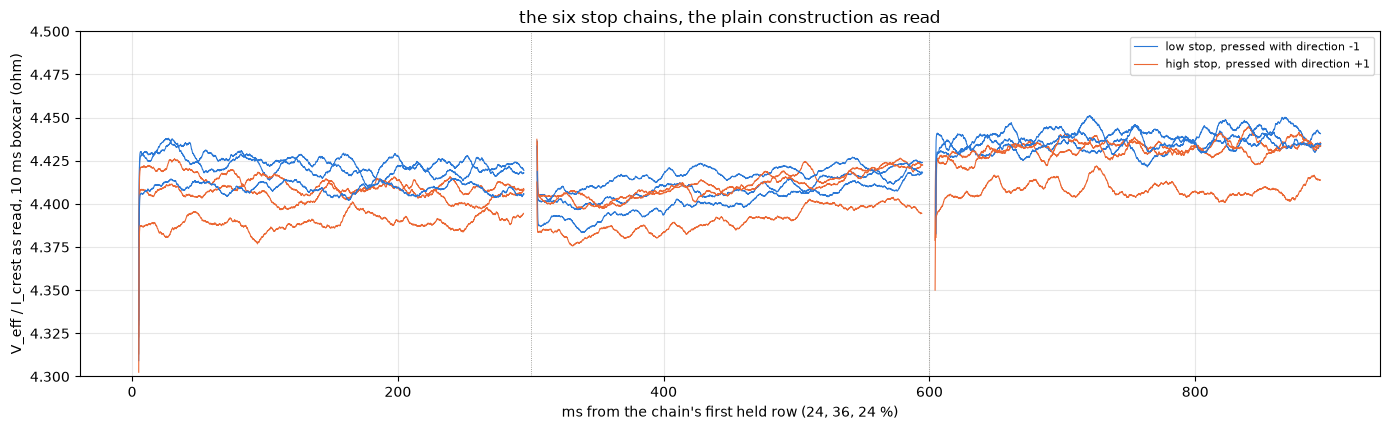

In [41]:
fig, ax = plt.subplots(figsize=(14, 4.4))
for k, g in T.groupby("chain"):
    stop = g["stop"].iloc[0]
    offset = 0.0                        # s, where this step starts
    for step in (1, 2, 3):
        s = STOP_TRACES[(k, step)]
        keep, ratio = smooth_ratio(s["volts"], s["amps"])
        named = step == 1 and k < 2     # one legend entry a stop
        ax.plot((s["t"][keep] + offset) * 1e3, ratio, lw=0.8,
                color=STOP_COLOR[stop],
                label=(f"{stop} stop, pressed with direction "
                       f"{int(g['dir'].iloc[0]):+d}" if named else None))
        offset += s["t"][-1] + 1 / FS
for x in (300, 600):
    ax.axvline(x, **figures.EDGE_STYLE)     # the steps' boundaries
ax.set_ylim(4.3, 4.5)
ax.legend(fontsize=8)
figures.label(ax, x="ms from the chain's first held row (24, 36, 24 %)",
              y="V_eff / I_crest as read, 10 ms boxcar (ohm)",
              title="the six stop chains, the plain construction as read")
figures.finish(fig)

Each step runs flat, and the six chains sit within about 1 % of each other. Step 3 reads 0.26 to 0.62 % over step 1 in each chain, the chain's warmth held in the copper, which the two-point line cancels by averaging the two 24 % steps against the 36 % one.

### The two-level lines

Each chain's line through its two levels, from the settled and the first-row reads, with the least squares line through its three steps beside it.

In [42]:
LINES = pd.concat([chain_lines(T, "i_first_a", "v_first_v", "first row"),
                   chain_lines(T, "i_settled_a", "v_eff_settled_v",
                               "settled")], ignore_index=True)
SET = LINES[LINES["read"] == "settled"]         # the stop read
FIRST = LINES[LINES["read"] == "first row"]
show(LINES[["read", "chain", "stop", "r_bracket_ohm", "v0_bracket_v",
            "r_ls_ohm", "v0_ls_v", "rms_mv", "step3_over_step1_pct",
            "lever_per_a"]].round(4), n=None)
R_STOP, R_STOP_SD = SET["r_bracket_ohm"].mean(), SET["r_bracket_ohm"].std()
V0_STOP, V0_STOP_SD = SET["v0_bracket_v"].mean(), SET["v0_bracket_v"].std()
POOLED = laps.line(T["i_settled_a"], T["v_eff_settled_v"])   # the check
BY_STOP = SET.groupby("stop")[["r_bracket_ohm", "v0_bracket_v"]].mean()
print(f"stop read, settled, 6 chains: R {R_STOP:.4f} sd {R_STOP_SD:.4f}, "
      f"V0 {V0_STOP:+.4f} sd {V0_STOP_SD:.4f}; first row R "
      f"{FIRST['r_bracket_ohm'].mean():.4f}, V0 "
      f"{FIRST['v0_bracket_v'].mean():+.4f}")
print(f"pooled least squares through {POOLED['n']} points: R "
      f"{POOLED['slope']:.4f} +/- {POOLED['slope_se']:.4f}, V0 "
      f"{POOLED['intercept']:+.4f} +/- {POOLED['intercept_se']:.4f}, rms "
      f"{POOLED['rms'] * 1e3:.1f} mV")
print("by stop: " + ", ".join(f"{s} R {r['r_bracket_ohm']:.4f} V0 "
                              f"{r['v0_bracket_v']:+.4f}"
                              for s, r in BY_STOP.iterrows()))
print(f"step 3 over step 1: {SET['step3_over_step1_pct'].min():.2f} to "
      f"{SET['step3_over_step1_pct'].max():.2f} %")

,read,chain,stop,r_bracket_ohm,v0_bracket_v,r_ls_ohm,v0_ls_v,rms_mv,step3_over_step1_pct,lever_per_a
0,first row,0,low,4.340,0.022,4.340,0.022,0.461,0.102,1.258
1,first row,1,high,4.346,0.020,4.346,0.020,1.527,0.332,1.252
2,first row,2,low,4.371,0.017,4.371,0.017,1.725,0.376,1.253
3,first row,3,high,4.350,0.018,4.349,0.018,2.786,0.606,1.249
4,first row,4,low,4.316,0.028,4.316,0.028,2.621,0.574,1.259
5,first row,5,high,4.333,0.017,4.333,0.017,2.772,0.602,1.244
6,settled,0,low,4.367,0.016,4.367,0.016,1.207,0.262,1.253
7,settled,1,high,4.394,0.007,4.394,0.007,2.564,0.552,1.242
8,settled,2,low,4.388,0.011,4.388,0.011,1.579,0.341,1.248
9,settled,3,high,4.386,0.009,4.386,0.009,2.217,0.478,1.244


stop read, settled, 6 chains: R 4.3774 sd 0.0146, V0 +0.0111 sd 0.0047; first row R 4.3428, V0 +0.0202
pooled least squares through 18 points: R 4.3765 +/- 0.0154, V0 +0.0114 +/- 0.0047, rms 3.6 mV
by stop: high R 4.3845 V0 +0.0075, low R 4.3703 V0 +0.0148
step 3 over step 1: 0.26 to 0.62 %


Over the six chains, settled, the stop read is $R$ = 4.3774 ohm sd 0.0146 and $V_0$ = +0.0111 V sd 0.0047. The pooled least squares through all eighteen points agrees, 4.3765 +/- 0.0154 ohm and +0.0114 +/- 0.0047 V with 3.6 mV rms. The first-row read gives 4.3428 ohm and +0.0202 V, 0.8 % lower in $R$, a method systematic of that size on chained steps. The low stop reads 4.3703 ohm and +0.0148 V, the high stop 4.3845 ohm and +0.0075 V, 0.3 % apart and inside the chains' sd. The direction is confounded with the stop here, -1 always at the low stop, so neither the seat nor the direction separates. The stop route's lever is large, $1/I$ moves 1.246 per A between the levels, so 0.1 % of $V/I$ is 3.5 mV of $V_0$.

### The seats

On the left, the lock's seat through the locked laps, the probes before and after each sweep, the sweep's own baseline and the TEL `pos` through each lap, its median with the range. On the right, the stop seats per step on a symmetric log scale, with the free ends written in the servo dotted. The thing to see is how far each seat moves under a lap.

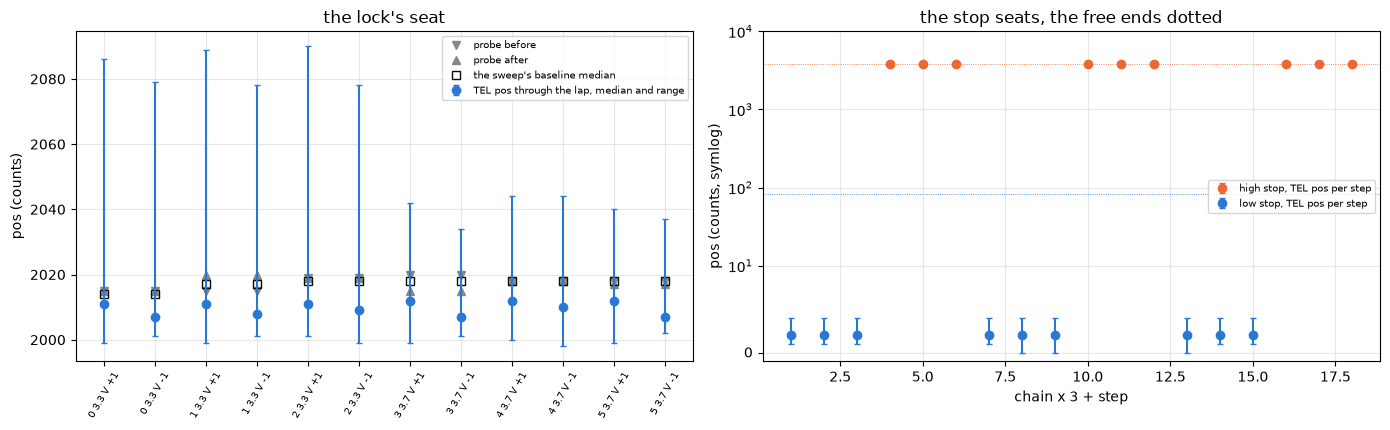

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
lap = np.arange(len(L))
ax[0].plot(lap, L["pos_before"], "v", color=MUTED, label="probe before")
ax[0].plot(lap, L["pos_after"], "^", color=MUTED, label="probe after")
ax[0].plot(lap, L["pos_rest"], "s", color=INK, mfc="none",
           label="the sweep's baseline median")
ax[0].errorbar(lap, L["pos_median"], yerr=[L["pos_median"] - L["pos_min"],
                                           L["pos_max"] - L["pos_median"]],
               fmt="o", color=BLUE, capsize=2,
               label="TEL pos through the lap, median and range")
ax[0].set_xticks(lap, [f"{c} {v:g} V {d:+d}" for c, v, d in
                       zip(L["chain"], L["volts_set"], L["dir"])],
                 rotation=60, fontsize=7)
figures.label(ax[0], y="pos (counts)", title="the lock's seat")
for stop, g in T.groupby("stop"):
    x = g["chain"] * 3 + g["step"]      # one slot per step
    ax[1].errorbar(x, g["pos_median"],
                   yerr=[g["pos_median"] - g["pos_min"],
                         g["pos_max"] - g["pos_median"]], fmt="o",
                   color=STOP_COLOR[stop], capsize=2,
                   label=f"{stop} stop, TEL pos per step")
for end, stop in zip(SERVO_ENDS, ("low", "high")):
    ax[1].axhline(end, color=STOP_COLOR[stop], lw=0.6, ls=":")
ax[1].set_yscale("symlog", linthresh=10)
ax[1].set_ylim(-1, 1e4)                 # counts, both ends in view
figures.label(ax[1], x="chain x 3 + step", y="pos (counts, symlog)",
              title="the stop seats, the free ends dotted")
for a in ax:
    a.legend(fontsize=7)
figures.finish(fig)

In [44]:
shift = L.drop_duplicates("chain")["pos_lap_shift"]
print(f"lock: seats.csv {SEATS_LOCKED['pos'].min()} to "
      f"{SEATS_LOCKED['pos'].max()} (median {SEATS_LOCKED['pos'].median():.0f})"
      f", shift per sweep {shift.abs().min():.0f} to {shift.abs().max():.0f}"
      f" counts; baseline {L['pos_rest'].min():.0f} to "
      f"{L['pos_rest'].max():.0f}; TEL median under the lap " + ", ".join(
          f"{d:+d} {g['pos_median'].min():.0f} to {g['pos_median'].max():.0f}"
          for d, g in L.groupby("dir")))
for stop, g in T.groupby("stop"):
    print(f"{stop} stop: TEL pos median {g['pos_median'].median():.0f} "
          f"({g['pos_min'].min():.0f} to {g['pos_max'].max():.0f} row to "
          f"row); the runner's seats "
          f"{sorted(g['seat_pos_runner'].unique().tolist())}")
print("stop seats.csv shifts:", SEATS_STOP["shift_counts"].tolist(),
      f"| board NTC {T['board_c'].min():.2f} to {T['board_c'].max():.2f} C")

lock: seats.csv 2015 to 2020 (median 2018), shift per sweep 0 to 5 counts; baseline 2014 to 2018; TEL median under the lap -1 2007 to 2010, +1 2011 to 2012
high stop: TEL pos median 3807 (3795 to 3817 row to row); the runner's seats [3806.0, 3807.0, 3808.0]
low stop: TEL pos median 2 (0 to 4 row to row); the runner's seats [2.0]
stop seats.csv shifts: [0, 0, 0, 1, 0, 2] | board NTC 26.00 to 26.04 C


At the lock the seat read 2015 to 2020 through the six sweeps, 0 to 5 counts per sweep, under the runner's 10 count rule. The sweeps' own baselines read 2014 to 2018, and the TEL median under a lap 2011 to 2012 in direction +1 and 2007 to 2010 in -1. That is the lock's give under 0.75 A, a few counts with the direction, about 0.25 degrees at the horn. The lock does not slip.

At the low stop the pot reads 0 to 4 through every step, on its ADC rail and about 80 counts past the free end at 82, so the seat there is blind. At the high stop it reads 3807 in the median, 3795 to 3817 row to row, 15 counts past the free end at 3792, and the runner's seats moved 0, 1 and 2 counts over the three chains. Both stoppers flex under the press, and both stops held the rotor through the chains, which the quiet current traces say where the pot does not. The board NTC read 26.00 to 26.04 C through the stop chains.

## The user's pass against the locked read

The stop read graded against $R_\mathrm{term}$, with the systematics the earlier notebooks carry, the window scale $k$ and the inductance notebook's crest bound.

In [45]:
I24 = T[T["step"] != 2]["i_settled_a"].mean()     # A, the 24 % level
I36 = T[T["step"] == 2]["i_settled_a"].mean()     # A, the 36 % level
V24 = T[T["step"] != 2]["v_eff_settled_v"].mean()
V36 = T[T["step"] == 2]["v_eff_settled_v"].mean()
STOP_LEVER = 1 / I24 - 1 / I36          # per A, between the two levels


def shifted(d24_ma, d36_ma):
    # the pooled two-level line with a crest over-read taken off each
    # level's current, mA
    i_lo, i_hi = I24 - d24_ma * 1e-3, I36 - d36_ma * 1e-3
    r = (V36 - V24) / (i_hi - i_lo)
    return r, V24 - r * i_lo


R_CREST_V, V0_CREST_V = shifted(CREST[24][0], CREST[36][0])   # value
R_CREST_B, V0_CREST_B = shifted(CREST[24][1], CREST[36][1])   # +2 sigma
PRED_AT_LOCK = R_STOP + V0_STOP / I_TERM    # ohm, V/I at 0.767 A
print(f"lever {STOP_LEVER:.3f} per A: 0.1 % of V/I moves V0 by "
      f"{0.001 * R_STOP / STOP_LEVER * 1e3:.1f} mV")
print(f"over k: R {R_STOP / K:.4f} ({R_STOP / K_HI:.4f} to "
      f"{R_STOP / K_LO:.4f}), V0 {V0_STOP / K:+.4f}")
print(f"the inductance crest bound: value R {R_CREST_V:.4f} V0 "
      f"{V0_CREST_V:+.4f}; +2 sigma R {R_CREST_B:.4f} V0 {V0_CREST_B:+.4f}"
      f" ({(R_CREST_B / R_STOP - 1) * 100:+.2f} %, "
      f"{(V0_CREST_B - V0_STOP) * 1e3:+.0f} mV)")
print(f"grade: stop R {(R_STOP / R_TERM - 1) * 100:+.2f} % on R_term; the "
      f"stop line's V/I at {I_TERM:.3f} A {PRED_AT_LOCK:.4f}, "
      f"{(PRED_AT_LOCK / R_TERM - 1) * 100:+.2f} % on it")

lever 1.246 per A: 0.1 % of V/I moves V0 by 3.5 mV
over k: R 4.3499 (4.3422 to 4.3576), V0 +0.0111
the inductance crest bound: value R 4.3688 V0 +0.0201; +2 sigma R 4.3469 V0 +0.0430 (-0.70 %, +32 mV)
grade: stop R +3.76 % on R_term; the stop line's V/I at 0.767 A 4.3920, +4.10 % on it


With the plain construction as read, the user's pass gives $R$ 3.76 % over $R_\mathrm{term}$, and the stop line's $V/I$ at the locked current, 4.3920 ohm, sits 4.10 % over it. Over the window scale $k$ the stop $R$ is 4.3499 ohm, still 3.1 % over. The inductance notebook's crest-to-mean bound, its recommended systematic, moves $R$ by -0.70 % and $V_0$ by +32 mV at its +2 sigma, to 4.3469 ohm and +0.0430 V, and at its value to 4.3688 ohm and +0.0201 V. None of these brings the stop read to the lock. The stop's lever fixes $V_0$ near zero, so a $V_0$ does not close the 4 % either. The user's pass with the plain construction does not reproduce the locked read, with high confidence.

## The three reads under one line

Three reads of this motor's resistance exist on this board. The locked 100 % laps give 3.234 V at 0.767 A, with nothing switching and no construction. The stop chains give two levels on one rail, as read 1.146 V at 0.259 A and 1.689 V at 0.383 A. The sag notebook's stop laps, quoted, give 4.344 ohm at 0.330 A at 1.5 V effective on thirteen rails, one seat at the low stop, about three hours into sitting 1, flat with the rail. The question is whether one line $V = V_0 + R\,I$ fits all three, and under which construction of the partial-duty reads.

The constructions are the as-read one, each stage 1 board term alone, both together, both with the edge lags and the loop at stage 1's bounds, and both with the type's crest term at its locked and spinning $G$. For each, the stop steps are rebuilt and each chain's two-point line read again. The sag laps' as-read $V/I$ is moved by the same construction at the duty the plan commanded on each rail, round(150 / rail) %, with $V_\mathrm{on}$ the rail less the sag notebook's 282 mV. The slope a construction predicts for the sag laps is the as-read slope a flat true $R$ would show under it.

In [46]:
RAILS_SAG = np.arange(8.4, 5.99, -0.2)          # V, the sag's 13 rails
DUTY_SAG = np.round(150 / RAILS_SAG) / 100      # the plan's 1.5 V duty
VON_SAG = RAILS_SAG - VON_GAP                   # V, their crest V_on
VEFF_SAG = DUTY_SAG * VON_SAG                   # V, as the sag read them
V_LOCK = R_TERM * I_TERM                        # V, the locked point
EB = {"edge_ticks": EDGE, "loop_ohm": LOOP["value"]}    # both board terms
VARIANTS = {
    "as read": {},
    "edge lags only": {"edge_ticks": EDGE},
    "brake drop only": {"loop_ohm": LOOP["value"]},
    "edge + brake": EB,
    "edge + brake, lags low": {**EB, "edge_ticks": EDGE_LO},
    "edge + brake, lags high": {**EB, "edge_ticks": EDGE_HI},
    "edge + brake, loop lo": {**EB, "loop_ohm": LOOP["lo"]},
    "edge + brake, loop hi": {**EB, "loop_ohm": LOOP["hi"]},
    "edge + brake + G locked": {**EB, "g_s": G_LOCKED},
    "edge + brake + G spinning": {**EB, "g_s": G_SPIN},
}
print(f"the locked point {V_LOCK:.4f} V at {I_TERM:.4f} A")
print(f"sag rails {RAILS_SAG[0]:.1f} to {RAILS_SAG[-1]:.1f} V at "
      f"{DUTY_SAG.min() * 100:.0f} to {DUTY_SAG.max() * 100:.0f} %; "
      f"{len(VARIANTS)} constructions")

the locked point 3.2344 V at 0.7666 A
sag rails 8.4 to 6.0 V at 18 to 25 %; 10 constructions


In [47]:
def stop_under(kw):
    # the stop steps' volts and current under one construction, and each
    # chain's two-point line through them
    v, i = construct(T["duty_pct"].to_numpy() / 100,
                     T["v_on_settled_v"].to_numpy(),
                     T["i_settled_a"].to_numpy(), **kw)
    s = T.assign(v_c=v, i_c=i)
    lines = []
    for k, g in s.groupby("chain"):
        low, high = g[g["step"] != 2], g[g["step"] == 2].iloc[0]
        i_lo, v_lo = low["i_c"].mean(), low["v_c"].mean()
        r = (high["v_c"] - v_lo) / (high["i_c"] - i_lo)
        lines.append({"chain": k, "stop": g["stop"].iloc[0], "r": r,
                      "v0": v_lo - r * i_lo, "i_lo": i_lo, "v_lo": v_lo,
                      "i_hi": high["i_c"], "v_hi": high["v_c"]})
    return s, pd.DataFrame(lines)


def sag_under(kw):
    # the sag laps under one construction: each rail's V/I moved from the
    # quoted flat read, the winding current, and the rail slope the terms
    # predict for an as-read V/I over a flat true R
    v_c, i_c = construct(DUTY_SAG, VON_SAG, I_SAG, **kw)
    vi = R_SAG * (v_c / i_c) / (VEFF_SAG / I_SAG)
    as_read = (VEFF_SAG / I_SAG) / (v_c / i_c)
    slope = np.polyfit(RAILS_SAG, as_read * vi.mean(), 1)[0]
    return vi, i_c, slope

In [48]:
def joint_line(s, vi_sag, i_sag):
    # V = V0 + R I through the lock's point, the stop's 18 points and the
    # sag's mean point, equal weights, and through lock and stop alone
    i_all = np.r_[I_TERM, s["i_c"].to_numpy(), i_sag.mean()]
    v_all = np.r_[V_LOCK, s["v_c"].to_numpy(), (vi_sag * i_sag).mean()]
    a = np.c_[np.ones_like(i_all), i_all]       # columns: V0, R
    (v0, r), *_ = np.linalg.lstsq(a, v_all, rcond=None)
    resid = v_all - a @ np.array([v0, r])
    (v0_2, r_2), *_ = np.linalg.lstsq(a[:-1], v_all[:-1], rcond=None)
    resid_2 = v_all[:-1] - a[:-1] @ np.array([v0_2, r_2])
    return {"joint_r": r, "joint_v0": v0,
            "joint_resid_lock_mv": resid[0] * 1e3,
            "joint_resid_stop_rms_mv": np.sqrt(np.mean(resid[1:-1] ** 2))
            * 1e3, "joint_resid_sag_mv": resid[-1] * 1e3,
            "lockstop_r": r_2, "lockstop_v0": v0_2,
            "lockstop_rms_mv": np.sqrt(np.mean(resid_2 ** 2)) * 1e3}

In [49]:
rows, POINTS, CHAIN_LINES = [], {}, {}
for name, kw in VARIANTS.items():
    s, lines = stop_under(kw)
    vi_sag, i_sag, slope = sag_under(kw)
    pred = 0.0 if not kw else slope     # as read predicts no slope
    r, v0 = lines["r"].mean(), lines["v0"].mean()
    rows.append({"variant": name, "r_stop": r, "r_stop_sd": lines["r"].std(),
                 "v0_stop": v0, "v0_stop_sd": lines["v0"].std(),
                 "stop_at_lock_pct": ((r + v0 / I_TERM) / R_TERM - 1) * 100,
                 "sag_over_stop_line_pct": (vi_sag.mean() / (
                     r + v0 / i_sag.mean()) - 1) * 100,
                 "sag_slope_predict": pred,
                 "sag_slope_sigma": (SAG_SLOPE["value"] - pred)
                 / SAG_SLOPE_SE, **joint_line(s, vi_sag, i_sag)})
    POINTS[name] = (s, vi_sag.mean(), i_sag.mean())
    CHAIN_LINES[name] = lines
V = pd.DataFrame(rows).set_index("variant")
show(V[["r_stop", "v0_stop", "stop_at_lock_pct", "sag_over_stop_line_pct",
        "sag_slope_predict", "sag_slope_sigma"]].round(4).reset_index(),
     n=None)
show(V[["joint_r", "joint_v0", "joint_resid_lock_mv",
        "joint_resid_stop_rms_mv", "joint_resid_sag_mv", "lockstop_r",
        "lockstop_v0", "lockstop_rms_mv"]].round(4).reset_index(), n=None)

,variant,r_stop,v0_stop,stop_at_lock_pct,sag_over_stop_line_pct,sag_slope_predict,sag_slope_sigma
0,as read,4.377,0.011,4.103,-1.522,0.000,-0.778
1,edge lags only,4.385,-0.042,2.649,-3.221,0.032,-5.278
2,brake drop only,4.261,-0.018,0.435,-2.375,0.007,-1.771
3,edge + brake,4.265,-0.070,-1.095,-4.195,0.041,-6.602
4,"edge + brake, lags low",4.260,-0.010,0.675,-2.101,0.002,-1.060
5,"edge + brake, lags high",4.269,-0.125,-2.684,-6.240,0.081,-12.257
6,"edge + brake, loop lo",4.272,-0.069,-0.852,-4.129,0.041,-6.511
7,"edge + brake, loop hi",4.249,-0.074,-1.570,-4.326,0.043,-6.782
8,edge + brake + G locked,4.206,-0.015,-0.767,-2.385,0.005,-1.490
9,edge + brake + G spinning,4.187,0.003,-0.656,-1.760,-0.008,0.361


,variant,joint_r,joint_v0,joint_resid_lock_mv,joint_resid_stop_rms_mv,joint_resid_sag_mv,lockstop_r,lockstop_v0,lockstop_rms_mv
0,as read,4.158,0.075,-27.996,13.478,-13.372,4.158,0.076,14.589
1,edge lags only,4.242,-0.002,-16.244,9.517,-38.083,4.243,0.000,9.781
2,brake drop only,4.236,-0.012,-1.102,4.303,-30.530,4.237,-0.011,3.875
3,edge + brake,4.322,-0.090,11.193,5.593,-55.383,4.323,-0.088,5.264
4,"edge + brake, lags low",4.223,-0.000,-3.030,4.549,-26.632,4.223,0.001,4.257
5,"edge + brake, lags high",4.411,-0.171,23.970,9.661,-81.210,4.412,-0.167,10.018
6,"edge + brake, loop lo",4.317,-0.085,9.412,5.180,-54.259,4.318,-0.082,4.681
7,"edge + brake, loop hi",4.332,-0.101,14.676,6.579,-57.579,4.333,-0.099,6.568
8,edge + brake + G locked,4.247,-0.028,7.062,4.582,-31.056,4.247,-0.027,4.455
9,edge + brake + G spinning,4.221,-0.007,5.783,4.297,-22.889,4.221,-0.006,4.219


As read there is no single line. The stop line predicts the lock's $V/I$ 4.1 % high, and a joint line through all three reads leaves the lock 28 mV under it, the stop points 13 mV rms off and the sag point 13 mV under. A $V_0$ does not do it, since the stop levels fix $V_0$ at +0.011 V. A constant crest offset does not either, since it moves the stop line's intercept and not the 3.8 % gap in its slope. Temperature does not, at 26.0 C at the stops and 26.3 C at the lock.

With both board terms at stage 1's values the stop chains read $R$ = 4.2647 ohm sd 0.0149 and $V_0$ = -0.0705 V, and the stop line lands 1.09 % under the lock's $V/I$. Lock and stop then fit one line, 4.323 ohm and -0.088 V with 5.3 mV rms. The sag laps sit 4.2 % under that line, and their flat rail slope is 6.6 sigma from the +0.041 ohm per volt the two terms predict. The board terms depend on the rail. At a fixed 1.5 V effective the duty falls from 25 to 18 % across the sag's rails, the edge term grows as $1/D$ and the brake term as $1 - D$, so a flat true $R$ would read +0.041 ohm per volt as read, where the sag laps measured -0.0055 +/- 0.0071. Adding the type's crest term at its spinning $G$ brings the predicted slope to -0.008, 0.4 sigma, and then the lock, the eighteen stop points and the sag's mean fit one line, $R$ = 4.221 ohm and $V_0$ = -0.007 V. The lock sits 6 mV off it, the stop points 4 mV rms and the sag point 23 mV under, 1.8 %, from one seat and one commutator angle, inside the type's angle spread and not a finding.

With the edge lags at the bounds' low end, -4 ticks, the brake term and no crest term, the stop chains give $R$ = 4.260 ohm and $V_0$ = -0.010 V, the lock within +0.7 %, a predicted sag slope of +0.002, 1.1 sigma, and the sag laps 2.1 % under the stop line.

### The inductance notebook's second reading, and the crest term the sag slope asks for

With the board terms in, the rail-independent crest offset that would close the stop levels with the lock, and the per-volt crest term that would bring the board terms' predicted sag slope to the measured one.

In [50]:
s_eb, _ = stop_under(EB)               # the stop steps, both terms
i24 = s_eb[s_eb["step"] != 2]["i_c"].mean()
v24 = s_eb[s_eb["step"] != 2]["v_c"].mean()
i36 = s_eb[s_eb["step"] == 2]["i_c"].mean()
v36 = s_eb[s_eb["step"] == 2]["v_c"].mean()
r_two = (v36 - v24) / (i36 - i24)       # ohm, an offset leaves the slope
v0_app = v24 - r_two * i24              # V, = V0 - R x offset
v0_true = V_LOCK - r_two * I_TERM       # V, the lock carries no offset
OFFSET_A = (v0_true - v0_app) / r_two   # A, the offset that closes them
print(f"edge + brake: the stop levels' slope {r_two:.4f} ohm, apparent V0 "
      f"{v0_app:+.4f} V, the lock at that slope {v0_true:+.4f} V, so a "
      f"rail-independent crest offset of {OFFSET_A * 1e3:+.1f} mA closes "
      "lock and stop")
pred_eb = V.loc["edge + brake", "sag_slope_predict"]
pred_g = V.loc["edge + brake + G locked", "sag_slope_predict"]
per_s = (pred_g - pred_eb) / G_LOCKED   # ohm/V per S of the crest term


def g_for(slope):
    # S, the crest term that brings the board terms' slope to `slope`
    return (slope - pred_eb) / per_s


G_NEEDED = g_for(SAG_SLOPE["value"])
G_LO, G_HI = sorted(g_for(SAG_SLOPE["value"] + e * SAG_SLOPE_SE)
                    for e in (-1, 1))   # S, the term falls as the slope rises
print(f"the sag slope under the board terms asks for a crest term of "
      f"{G_NEEDED * 1e3:.2f} mS ({G_LO * 1e3:.2f} to {G_HI * 1e3:.2f} from "
      f"its se); the type's locked {G_LOCKED * 1e3:.2f}, spinning "
      f"{G_SPIN * 1e3:.2f} mS")

edge + brake: the stop levels' slope 4.2647 ohm, apparent V0 -0.0705 V, the lock at that slope -0.0351 V, so a rail-independent crest offset of +8.3 mA closes lock and stop
the sag slope under the board terms asks for a crest term of 3.22 mS (2.73 to 3.71 from its se); the type's locked 2.49, spinning 3.35 mS


The inductance notebook left two readings of the sag slope alive, a held loss term bounded near zero and a crest offset that does not depend on the rail. With the board terms in, an offset of +8.3 mA on the crest current closes the stop levels' slope and intercept with the lock. An offset leaves the sag laps' slope at the board terms' +0.041 ohm per volt, so the sag laps reject it at 6.6 sigma if the board terms stand. At one rail an offset and a per-volt term act alike, so the stop chains alone say nothing about it, and the sag's rails are what separate them. A per-volt crest term of 3.22 mS, 2.73 to 3.71 over the sag slope's standard error, brings the board terms' prediction to the measured slope. That is the size of the type's spinning $G$, 3.35 mS, and above its locked-burst $G$, 2.49 mS.

The stop steps as applied volts against winding current under three constructions, as read in gray, with both board terms in blue and with the spinning crest term added in green, each with the chains' mean line, and the locked laps' point as a star. The thing to see is which line passes through the star.

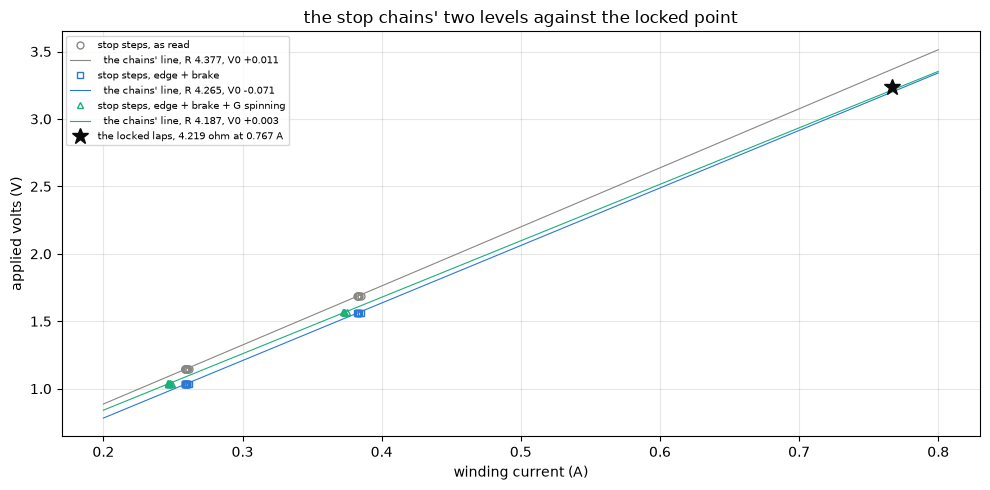

In [51]:
SHOWN = (("as read", MUTED, "o"), ("edge + brake", BLUE, "s"),
         ("edge + brake + G spinning", GREEN, "^"))
fig, ax = plt.subplots(figsize=(10, 5))
amps = np.array([0.2, 0.8])             # A, the lines' span
for name, color, marker in SHOWN:
    s = POINTS[name][0]
    ax.plot(s["i_c"], s["v_c"], marker, ms=5, color=color, mfc="none",
            label=f"stop steps, {name}")
    r, v0 = V.loc[name, "r_stop"], V.loc[name, "v0_stop"]
    ax.plot(amps, v0 + r * amps, color=color, lw=0.8,
            label=f"  the chains' line, R {r:.3f}, V0 {v0:+.3f}")
ax.plot(I_TERM, V_LOCK, "*", ms=12, color=INK,
        label=f"the locked laps, {R_TERM:.3f} ohm at {I_TERM:.3f} A")
ax.legend(fontsize=7)
figures.label(ax, x="winding current (A)", y="applied volts (V)",
              title="the stop chains' two levels against the locked point")
figures.finish(fig)

As read, the stop line passes about 0.13 V over the star at the locked current. With the board terms it passes just under it, 1.1 % in $V/I$, and with the crest term added 0.7 % under it.

Each chain's own line under the as-read construction and with both board terms, from the stop levels out to the locked current, the bracket points circled and colored by stop. The thing to see is how tight the six lines are against their distance from the star.

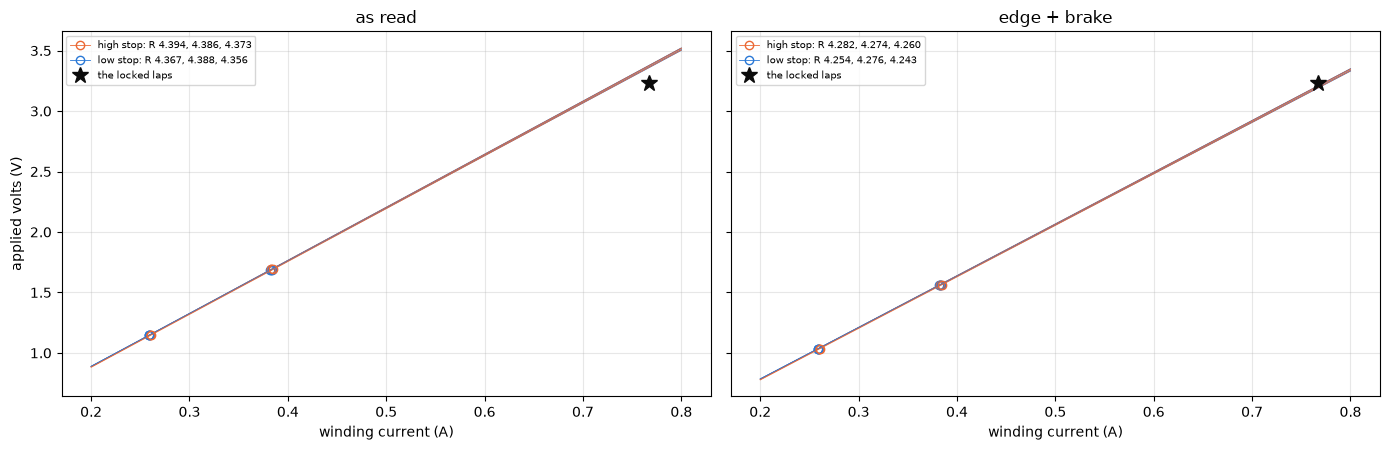

the chains' lines at the locked current, less the lock's volts: as read +123 to +141 mV; edge + brake -46 to -27 mV


In [52]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
span = np.array([0.2, 0.8])             # A, from the stop levels to the lock
for axis, name in zip(ax, ("as read", "edge + brake")):
    for _, c in CHAIN_LINES[name].iterrows():
        color = STOP_COLOR[c["stop"]]
        axis.plot(span, c["v0"] + c["r"] * span, color=color, lw=0.6)
        axis.plot([c["i_lo"], c["i_hi"]], [c["v_lo"], c["v_hi"]], "o",
                  color=color, mfc="none", ms=6)   # the bracket points
    for stop, g in CHAIN_LINES[name].groupby("stop"):
        axis.plot([], [], "o-", mfc="none", lw=0.6, color=STOP_COLOR[stop],
                  label=f"{stop} stop: R " + ", ".join(
                      f"{r:.3f}" for r in g["r"]))
    axis.plot(I_TERM, V_LOCK, "*", ms=12, color=INK,
              label="the locked laps")
    axis.legend(fontsize=7, loc="upper left")
    figures.label(axis, x="winding current (A)", title=name)
figures.label(ax[0], y="applied volts (V)")
figures.finish(fig)
at_lock = {n: (CHAIN_LINES[n]["v0"] + CHAIN_LINES[n]["r"] * I_TERM)
           for n in ("as read", "edge + brake")}
print("the chains' lines at the locked current, less the lock's volts: "
      + "; ".join(f"{n} {(v - V_LOCK).min() * 1e3:+.0f} to "
                  f"{(v - V_LOCK).max() * 1e3:+.0f} mV"
                  for n, v in at_lock.items()))

At the locked current the six as-read lines sit 123 to 141 mV over the lock's volts, and with both board terms 27 to 46 mV under. The chains spread by under 20 mV under either construction, so the gap to the star belongs to the construction and not to a chain.

Every read on one plot of $V/I$ against $1/I$. On this plot a line $V = V_0 + R\,I$ is a straight line with slope $V_0$ and intercept $R$, so the dotted guides through the locked point are the lines with $V_0$ of -0.1, 0 and +0.1 V. The locked laps, the stop steps and the sag point are drawn under three constructions, with the type motors' $R_\mathrm{term}$ as horizontal lines. The thing to see is which construction puts the stop steps and the sag point on one guide with the locked laps.

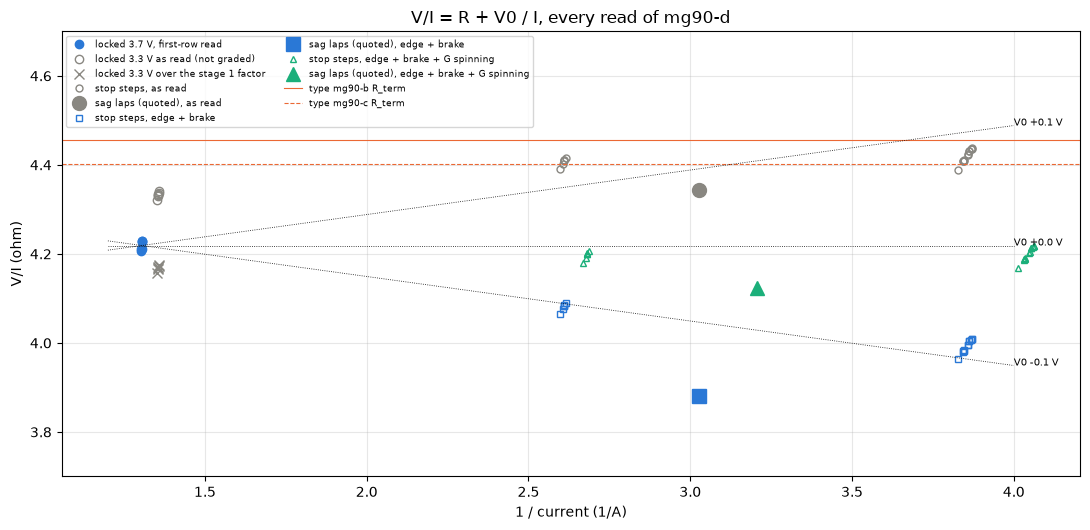

In [53]:
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.plot(1 / G3["i_first_a"], G3["r_first_ohm"], "o", color=BLUE, ms=6,
        label="locked 3.7 V, first-row read")
ax.plot(1 / LOW["i_first_a"], LOW["r_first_ohm"], "o", color=MUTED,
        mfc="none", ms=6, label="locked 3.3 V as read (not graded)")
ax.plot(1 / LOW["i_first_a"], LOW["r_first_ohm"] / F_3V3, "x",
        color=MUTED, ms=7, label="locked 3.3 V over the stage 1 factor")
for name, color, marker in SHOWN:
    s, vi_sag, i_sag = POINTS[name]
    ax.plot(1 / s["i_c"], s["v_c"] / s["i_c"], marker, ms=5, color=color,
            mfc="none", label=f"stop steps, {name}")
    ax.plot(1 / i_sag, vi_sag, marker, ms=10, color=color,
            label=f"sag laps (quoted), {name}")
for key, rr in TYPES.items():
    ax.axhline(rr["r_term_median_ohm"]["value"], color=ORANGE, lw=0.8,
               ls="--" if key == "mg90-c" else "-",
               label=f"type {key} R_term")
inv = np.array([1.2, 4.0])              # 1/A, the guides' span
for v0 in (-0.1, 0.0, 0.1):             # V, guides through the lock
    ax.plot(inv, R_TERM + v0 * (inv - 1 / I_TERM), color=INK, lw=0.6,
            ls=":")
    ax.annotate(f"V0 {v0:+.1f} V", (inv[1], R_TERM + v0 * (inv[1]
                                   - 1 / I_TERM)), fontsize=7)
ax.set_ylim(3.7, 4.7)
ax.legend(fontsize=6.5, ncol=2, loc="upper left")
figures.label(ax, x="1 / current (1/A)", y="V/I (ohm)",
              title="V/I = R + V0 / I, every read of mg90-d")
figures.finish(fig)

As read the stop steps sit near 4.41 ohm, over the 3.3 V locked laps and over every guide through the lock, and the sag point sits under the stop steps. With both board terms the stop steps drop to about the -0.1 V guide and the sag point falls well under it. With the spinning crest term added the stop steps and the sag point sit close to the 0 V guide through the lock, the joint line above. The type motors' lines sit 4 to 5 % over mg90-d's 3.7 V locked laps.

For each construction, on the left, the stop line's $V/I$ at the locked current over the lock and the sag laps over the stop line, in percent, and on the right the rail slope the construction predicts for a flat true $R$ against the sag laps' measured slope with its standard error shaded. The thing to see is which constructions keep the three reads within a percent or two and the slope inside the band.

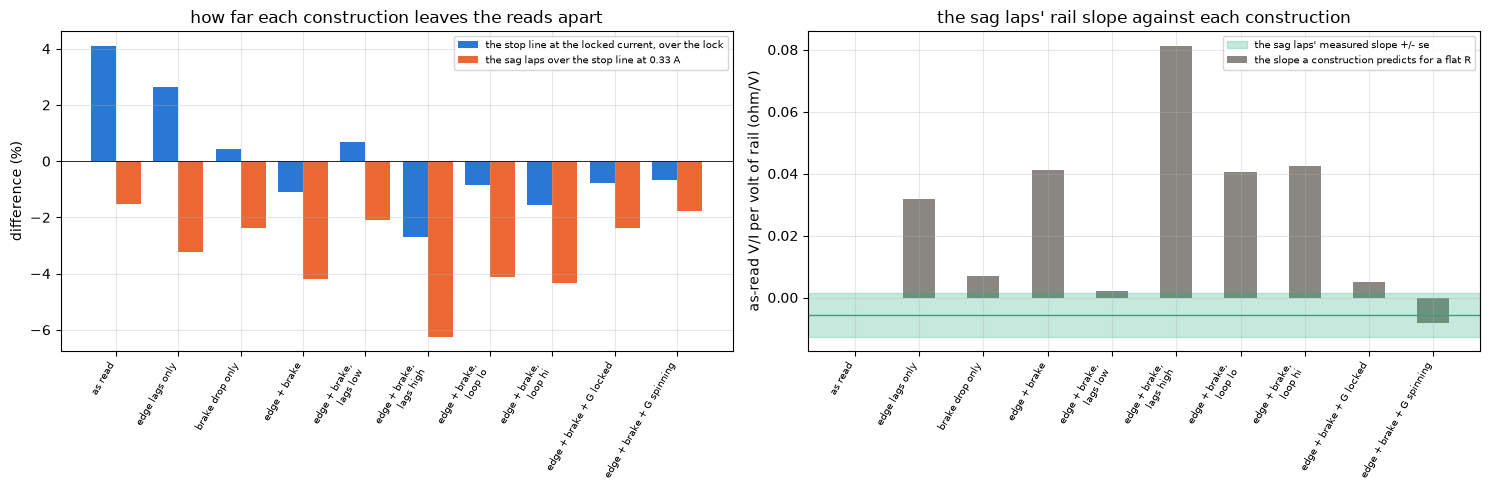

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(V))
names = [n.replace(", ", ",\n") for n in V.index]
ax[0].bar(x - 0.2, V["stop_at_lock_pct"], 0.4, color=BLUE,
          label="the stop line at the locked current, over the lock")
ax[0].bar(x + 0.2, V["sag_over_stop_line_pct"], 0.4, color=ORANGE,
          label="the sag laps over the stop line at 0.33 A")
ax[0].axhline(0, color=INK, lw=0.6)
ax[0].legend(fontsize=7)
figures.label(ax[0], y="difference (%)",
              title="how far each construction leaves the reads apart")
ax[1].bar(x, V["sag_slope_predict"], 0.5, color=MUTED,
          label="the slope a construction predicts for a flat R")
ax[1].axhspan(SAG_SLOPE["lo"], SAG_SLOPE["hi"], color=GREEN, alpha=0.25,
              label="the sag laps' measured slope +/- se")
ax[1].axhline(SAG_SLOPE["value"], color=GREEN, lw=1)
ax[1].legend(fontsize=7)
figures.label(ax[1], y="as-read V/I per volt of rail (ohm/V)",
              title="the sag laps' rail slope against each construction")
for a in ax:
    a.set_xticks(x, names, rotation=60, ha="right", fontsize=7)
figures.finish(fig)

Four constructions keep the predicted sag slope within 2 sigma of the measurement and the stop line within 1 % of the lock. They are the brake drop alone, both terms with the edge lags at their low bound, and both terms with either of the type's crest terms. The brake drop alone is the edge lags at zero ticks, inside the second reading below. Both board terms at stage 1's values with no crest term put the stop line within 1.1 % of the lock and the slope 6.6 sigma off.

### Stage 1's check of the construction

The same constructions on stage 1's own data, quoted as a check of the construction and not of the motor. Bridge-states ran slow-decay rungs at 25 and 40 % into the RL dummy, a resistor and an inductor with no brushes, in three inductive wirings and both directions, with each wiring's DC resistance from its own 100 % rungs. A construction that leaves nothing out reads that DC resistance. The stage 1 notebook should own this number if it is quoted. Its result file does not carry it, and its `window_r_ohm` and `window_scale` are the burst estimator's, which already carries both terms.

In [55]:
DUMMY = PAIR_DIR.parent / BOARD_KEY / "bridge-states" / "capture-1"
rows = []
for w in ("ra", "rab", "rb"):           # the RL dummy's inductive wirings
    dc = BRIDGE["dc_r_ohm"][w]["value"] # ohm, its own 100 % read
    df, _ = tel.load(DUMMY / w / "sweep-slow", BOARD)
    zero_i, _ = tel.rest_zeros(df)
    for seg, g in df[df["seg"] > 0].groupby("seg"):
        gh, held, _ = held_rows(g)
        d = int(gh["dir"].iloc[0])
        on = np.arange(len(gh)) / FS >= DUMMY_FROM_S    # settled rows
        i = SCALES.amps(gh["current_raw"].to_numpy(float), zero_i)[on].mean()
        taps = ((gh["vmotor_a"] - gh["vmotor_b"]) * d).to_numpy(float)
        v_on = SCALES.volts(taps, TAP_OFFSET)[on].mean()
        duty = abs(held) / ARR
        d_edge = (2 * abs(held) - EDGE) / (2 * ARR)     # D prime
        v = {"plain": duty * v_on, "edge": d_edge * v_on,
             "brake": duty * v_on - (1 - duty) * LOOP["value"] * i,
             "both": d_edge * v_on - (1 - d_edge) * LOOP["value"] * i}
        rows.append({"wiring": w, "dir": d, "duty_pct": duty * 100,
                     **{f"{n}_pct": (u / i / dc - 1) * 100
                        for n, u in v.items()}})
DUM = pd.DataFrame(rows)
DUM = DUM[DUM["duty_pct"] < 100]        # the 100 % rungs are the DC R
COLS = ["plain_pct", "edge_pct", "brake_pct", "both_pct"]
show(DUM.groupby("duty_pct")[COLS].agg(["min", "max"]).round(2)
     .reset_index(), n=None)

duty_pct plain_pct       edge_pct       brake_pct       both_pct       
                 min   max      min   max       min   max      min    max
0   25.000     8.300 8.830    3.700 4.200     3.980 4.510   -0.680 -0.180
1   40.000     5.080 5.470    2.290 2.670     1.630 2.100   -1.230 -0.770

On the RL dummy the plain construction reads 8.30 to 8.83 % over the DC resistance at 25 % and 5.08 to 5.47 % at 40 %. The edge lags alone leave 3.70 to 4.20 and 2.29 to 2.67 %, the brake drop alone 3.98 to 4.51 and 1.63 to 2.10 %, and both together -0.18 to -0.68 and -0.77 to -1.23 %. On a load with no brushes the two board terms account for the plain construction's excess to within about 1 %. That is stage 1's check to own, and nothing here is derived from it.

Each rung of the dummy as $V/I$ over its wiring's DC resistance under the four constructions, against the duty. The thing to see is where each construction lands against zero.

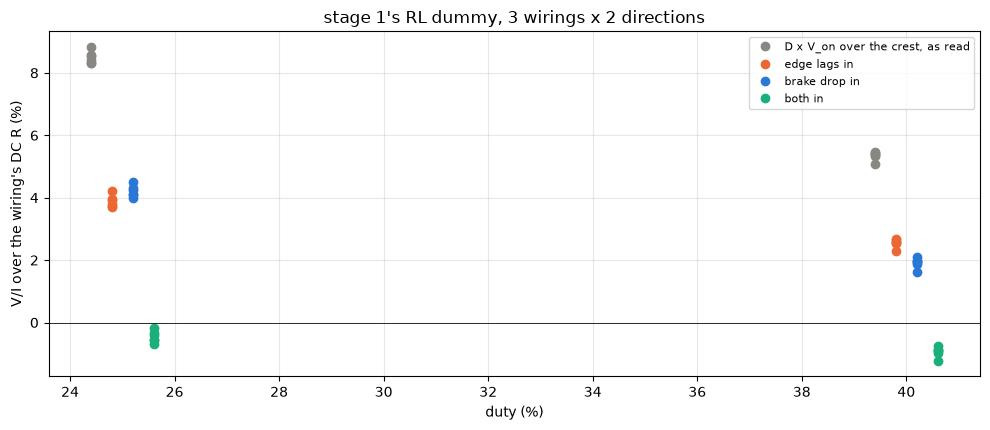

In [56]:
fig, ax = plt.subplots(figsize=(10, 4.4))
nudge = {"plain_pct": -0.6, "edge_pct": -0.2, "brake_pct": 0.2,
         "both_pct": 0.6}               # % of duty, so the dots part
names = {"plain_pct": "D x V_on over the crest, as read",
         "edge_pct": "edge lags in", "brake_pct": "brake drop in",
         "both_pct": "both in"}
for col, color in zip(COLS, (MUTED, ORANGE, BLUE, GREEN)):
    ax.plot(DUM["duty_pct"] + nudge[col], DUM[col], "o", ms=6,
            color=color, label=names[col])
ax.axhline(0, color=INK, lw=0.6)
ax.legend(fontsize=8)
figures.label(ax, x="duty (%)", y="V/I over the wiring's DC R (%)",
              title="stage 1's RL dummy, 3 wirings x 2 directions")
figures.finish(fig)

### Two readings

As read, the three reads have no common line. With stage 1's two board terms at their stated values the stop chains come within about 1 % of the lock, but the sag slope sits 6.6 sigma off. Two readings of the partial-duty reads stand.

1. Leading, moderate. The partial-duty reads carry the two stage 1 board terms and a crest over-read of about 3.2 mS per volt of $(1 - D)\,V_\mathrm{on}$, the size of the type's spinning $G$. The motor's line is then $R$ = 4.19 to 4.22 ohm and $V_0$ = -0.01 to 0.00 V, and the user's pass with the three terms reproduces the locked read within 1 %.
2. Alive, low to moderate. The edge lags on the motor at 18 to 36 % are smaller than the bare load's 25.5 ticks, the bounds reaching -4, the brake term stands and no crest term enters. At the low bound the stop chains give $R$ = 4.260 ohm and $V_0$ = -0.010 V, the lock within +0.7 %, the sag slope predicted at +0.002 ohm per volt, 1.1 sigma, and the sag laps 2.1 % under the stop line.

Dead are a constant crest offset as the whole difference, since it leaves the slope mismatch and the sag slope rejects it at 6.6 sigma if the board terms stand, $V_0$ alone, since the stop lever fixes it near zero as read, and temperature, at 26.0 against 26.3 C.

The kill test is the same stop chains at a second rail, 3.7 V at 32 and 49 % and 7.4 V at 16 and 24 %, at the same two currents. The edge term goes as $1/D$, the brake term as $1 - D$ and the crest term as $(1 - D)\,V_\mathrm{on}$, so four levels on two rails separate the three with no meter. Folding the taps' edges on a burst recording at the stop at 24 and 36 % would test the edge lags on their own, since the TEL rows carry the crest only.

The first reading reverses the inductance notebook's recommendation. That notebook told the stop chains to take no crest-to-mean correction, from a held-loss bound of 0.42 mS (-0.66 to 1.50) read off the sag laps' slope. Its bound was the same slope read without the board terms. With the board terms the same slope asks for a crest term of about 3.2 mS. So the two notebooks disagree on the crest correction at partial duty, and the next capture, the stop chains at a second rail, decides it. Under the second reading the inductance notebook's recommendation stands.

These data pin $V_0$ no better than about +/-0.06 V and $R$ no better than 1 % across the constructions. The locked 4.2189 ohm at 0.767 A is the number no construction enters.

## Results

The headline is the locked read, $R_\mathrm{term}$ = 4.219 ohm, sd 0.011, at 0.767 A, with $V_0$ inside it, from the 100 % laps where no construction enters. The locked two-level line is report-only, since its lever leaves no room for a $V_0$. The stop keys carry the plain construction as read, the user's pass with what the board reads. The keys named `edge_brake` and `edge_brake_g` carry stage 1's board terms and the type's crest term as the readings above, candidates and not corrections.

The result file keeps stage 2 rest-resistance's key names and shapes wherever the quantity is the same. Those are `r_term_median_ohm`, `r_term_lap_scatter_pct`, `r_term_amps`, `direction_gap_pct`, `warming_pct_per_j`, `copper_heat_capacity_max_j_per_c`, `copper_mass_max_g`, `v_over_i_3v3_excess_pct`, `v_over_i_3v3_stage1_pct`, `v0_all_rails_v`, `v0_all_rails_scaled_v`, `r_stall_all_rails_ohm`, `lap_joules` and `board_ntc_c`. No holes were run, so the `*_by_hole`, `hole_map_*` and `r_term_angle_pct` keys are out and the by-direction and by-chain keys take their place. `r_term_ohm`, the mean over the six laps, is the headline key, and `r_term_median_ohm` the median of the same laps for stage 2's key.

In [57]:
q = results.quantity
pm = results.pm
R_FIRST = G3["r_first_ohm"]             # ohm, the six 3.7 V laps
OUT = {
    "r_term_ohm": q(R_TERM, R_FIRST.min(), R_FIRST.max(), "ohm"),
    "r_term_median_ohm": results.median_range(R_FIRST, "ohm"),
    "r_term_lap_scatter_pct": q(R_TERM_SD / R_TERM * 100, unit="%"),
    "r_term_amps": q(I_TERM, G3["i_first_a"].min(), G3["i_first_a"].max(),
                     "A"),
}
for d, name in ((1, "fwd"), (-1, "rev")):
    r = G3[G3["dir"] == d]["r_first_ohm"]
    OUT[f"r_term_by_direction_ohm_{name}"] = q(r.mean(), r.min(), r.max(),
                                               "ohm")
for v, key in ((3.7, "direction_gap_pct"), (3.3, "direction_gap_pct_3v3")):
    g = GAPS.xs(v, level="volts_set")["gap_pct"]
    OUT[key] = q(g.mean(), g.min(), g.max(), "%")
P = G3["r_plateau_ohm"]
OUT["r_term_plateau_ohm"] = q(R_PLATEAU, P.min(), P.max(), "ohm")
OUT["r_term_plateau_less_copper_ohm"] = q(R_PLATEAU_COLD, unit="ohm")
r = LOW["r_first_ohm"]
OUT["r_3v3_ohm"] = q(r.mean(), r.min(), r.max(), "ohm")
OUT["v_over_i_3v3_excess_pct"] = q(EXCESS_ALL, EXCESS_3V3.min(),
                                   EXCESS_3V3.max(), "%")
OUT["v_over_i_3v3_stage1_pct"] = q((F_3V3 - 1) * 100, unit="%")
OUT["v0_two_level_lever_mv_per_0p1pct"] = q(MV_PER_0P1, unit="mV")
for name, key in (("as read", ""), ("scaled", "_scaled")):
    line = LEVEL_LINES[name].set_index("dir").loc["both"]
    OUT[f"v0_all_rails{key}_v"] = pm(line["v0_v"], line["v0_se"], "V")
    OUT[f"r_stall_all_rails{key}_ohm"] = pm(line["r_ohm"], line["r_se"],
                                            "ohm")

In [58]:
for key, col, unit in (("free_spin_dip_pct", "dip_pct", "%"),
                       ("free_spin_emf_rev_s", "emf_dip_rev_s", "rev/s"),
                       ("free_spin_until_ms", "spin_until_ms", "ms")):
    OUT[key] = q(L[col].mean(), L[col].min(), L[col].max(), unit)
OUT["warming_pct_per_j"] = results.median_range(G3["pct_per_j"], "%/J",
                                                value=PCT_PER_J)
OUT["warming_pct_per_j_3v3"] = results.median_range(
    LOW["pct_per_j"], "%/J", value=LOW["pct_per_j"].mean())
OUT["copper_heat_capacity_max_j_per_c"] = q(C_MAX, unit="J/C")
OUT["copper_mass_max_g"] = q(C_MAX / C_CU, unit="g")
line_gate = QL[QL["window"] == "line 60-300"]["i_sd_counts"]
OUT["quiet_gate_i_sd_counts"] = q(line_gate.mean(), line_gate.min(),
                                  line_gate.max(), "counts")
OUT["lap_joules"] = results.median_range(L["joules"], "J",
                                         value=L["joules"].max())
OUT["board_ntc_c"] = results.median_range(L["board_c"], "C")
seat = SEATS_LOCKED["pos"]
OUT["seat_pos_lock"] = results.median_range(seat, "counts")
OUT["seat_shift_per_lap_counts"] = q(shift.abs().max(), shift.abs().min(),
                                     shift.abs().max(), "counts")
for key, tag in (("mg90-b", "mg90b"), ("mg90-c", "mg90c")):
    row = TYPE_GAP.loc[key]
    OUT[f"r_type_gap_pct_{tag}"] = q(row["gap_pct"], unit="%")
    OUT[f"r_type_gap_common_t_pct_{tag}"] = q(row["gap_at_common_t_pct"],
                                              unit="%")
print(len(OUT), "keys so far")

34 keys so far


In [59]:
OUT["r_stop_ohm"] = pm(R_STOP, R_STOP_SD, "ohm")
OUT["v0_stop_v"] = pm(V0_STOP, V0_STOP_SD, "V")
for key, col, unit in (("r_stop_first_row_ohm", "r_bracket_ohm", "ohm"),
                       ("v0_stop_first_row_v", "v0_bracket_v", "V")):
    OUT[key] = pm(FIRST[col].mean(), FIRST[col].std(), unit)
OUT["r_stop_pooled_ohm"] = results.line_q(POOLED, "slope", "ohm")
OUT["v0_stop_pooled_v"] = results.line_q(POOLED, "intercept", "V")
for stop in ("low", "high"):
    g = SET[SET["stop"] == stop]
    for key, col, unit in (("r_stop_by_stop_ohm", "r_bracket_ohm", "ohm"),
                           ("v0_stop_by_stop_v", "v0_bracket_v", "V")):
        OUT[f"{key}_{stop}"] = q(g[col].mean(), g[col].min(), g[col].max(),
                                 unit)
OUT["r_stop_by_chain_ohm"] = [round(float(v), 4)
                              for v in SET["r_bracket_ohm"]]
OUT["v0_stop_by_chain_v"] = [round(float(v), 4)
                             for v in SET["v0_bracket_v"]]
for kind, g in KIND:
    for key, col, unit in (("stop_step_amps", "i_settled_a", "A"),
                           ("stop_v_on_v", "v_on_settled_v", "V"),
                           ("stop_vi_as_read_ohm", "r_settled_ohm", "ohm")):
        OUT[f"{key}_{kind}"] = q(g[col].mean(), g[col].min(), g[col].max(),
                                 unit)
w = SET["step3_over_step1_pct"]
OUT["stop_chain_warming_pct"] = q(w.mean(), w.min(), w.max(), "%")
OUT["stop_lever_per_a"] = q(STOP_LEVER, unit="1/A")
OUT["r_stop_over_k_ohm"] = q(R_STOP / K, R_STOP / K_HI, R_STOP / K_LO,
                             "ohm")

In [60]:
OUT["r_stop_crest_bound_ohm"] = q(R_CREST_B, unit="ohm")
OUT["v0_stop_crest_bound_v"] = q(V0_CREST_B, unit="V")
OUT["r_stop_crest_value_ohm"] = q(R_CREST_V, unit="ohm")
OUT["v0_stop_crest_value_v"] = q(V0_CREST_V, unit="V")
eb = V.loc["edge + brake"]
OUT["r_stop_edge_brake_ohm"] = pm(eb["r_stop"], eb["r_stop_sd"], "ohm")
OUT["r_stop_edge_brake_loop_ohm"] = q(
    eb["r_stop"], V.loc["edge + brake, loop hi", "r_stop"],
    V.loc["edge + brake, loop lo", "r_stop"], "ohm")
OUT["r_stop_edge_brake_lags_ohm"] = q(
    eb["r_stop"], V.loc["edge + brake, lags low", "r_stop"],
    V.loc["edge + brake, lags high", "r_stop"], "ohm")
OUT["v0_stop_edge_brake_v"] = q(
    eb["v0_stop"], V.loc["edge + brake, lags high", "v0_stop"],
    V.loc["edge + brake, lags low", "v0_stop"], "V")
for g_name, tag in (("G spinning", "spin"), ("G locked", "locked")):
    row = V.loc[f"edge + brake + {g_name}"]
    OUT[f"r_stop_edge_brake_g_ohm_{tag}"] = q(row["r_stop"], unit="ohm")
    OUT[f"v0_stop_edge_brake_g_v_{tag}"] = q(row["v0_stop"], unit="V")
for name, tag in (("as read", "as_read"), ("edge + brake", "edge_brake"),
                  ("edge + brake + G spinning", "edge_brake_g_spin")):
    OUT[f"stop_over_locked_pct_{tag}"] = q(V.loc[name, "stop_at_lock_pct"],
                                           unit="%")
js = V.loc["edge + brake + G spinning"]
OUT["joint_r_ohm"] = q(js["joint_r"], unit="ohm")
OUT["joint_v0_v"] = q(js["joint_v0"], unit="V")
OUT["joint_resid_mv_lock"] = q(js["joint_resid_lock_mv"], unit="mV")
OUT["joint_resid_mv_stop_rms"] = q(js["joint_resid_stop_rms_mv"], unit="mV")
OUT["joint_resid_mv_sag"] = q(js["joint_resid_sag_mv"], unit="mV")

In [61]:
OUT["sag_slope_board_terms_predict_ohm_per_v"] = q(eb["sag_slope_predict"],
                                                    unit="ohm/V")
OUT["sag_slope_board_terms_sigma"] = q(eb["sag_slope_sigma"], unit="sigma")
OUT["sag_slope_g_needed_ms"] = q(G_NEEDED * 1e3, G_LO * 1e3, G_HI * 1e3,
                                 "mS")
OUT["reading2_offset_ma"] = q(OFFSET_A * 1e3, unit="mA")
for duty in (25, 40):
    g = DUM[DUM["duty_pct"].round() == duty]
    for col in ("plain", "both"):
        c = g[f"{col}_pct"]
        OUT[f"construction_check_dummy_pct_{col}_{duty}"] = q(
            c.mean(), c.min(), c.max(), "%")
OUT["edge_ticks"] = q(EDGE, EDGE_LO, EDGE_HI, "ticks")
OUT["low_side_loop_ohm"] = dict(LOOP)       # stage 1's, quoted
for stop in ("low", "high"):
    g = T[T["stop"] == stop]
    OUT[f"seat_pos_stop_{stop}"] = q(g["pos_median"].median(),
                                     g["pos_min"].min(), g["pos_max"].max(),
                                     "counts")
OUT["board_ntc_c_stop"] = q(T["board_c"].mean(), T["board_c"].min(),
                            T["board_c"].max(), "C")
t0 = manifest(SITTING["stop"])["t_host"].min()
OUT["stop_minutes_into_sitting"] = q((CH_STOP["t_start"].min() - t0) / 60,
                                     unit="min")
seek = first_steps["seek_i_a"]
OUT["stop_seek_amps"] = q(seek.mean(), seek.min(), seek.max(), "A")
print(len(OUT), "keys")

90 keys


### The result file

The notes that define every key, then the write.

In [62]:
NOTES = (
    "stage 3 resistance of mg90-d on dev-v006-2A-D from two datasets: "
    "resistance/locked-4 (sitting 4, the horn lock at mid travel, six "
    "sweeps 20 s apart, three on 3.3 V and three on 3.7 V, each 300 ms at "
    "100 % in direction +1 and, after a 20 s rest, 300 ms in -1) and "
    "resistance/stop-1 (sitting 1, 5.0 V, six chains 20 s apart of 24, 36 "
    "and 24 % for 300 ms each after a 49 % stall seek, chains 0, 2, 4 "
    "direction -1 into the low stop, 1, 3, 5 direction +1 into the high "
    "stop). Current and terminal volts through stage 1's current-scale "
    "and terminal-chain over each sweep's torque-off zero. A lap or step "
    "is read as stage 2 rest-resistance reads a lap: from its first row "
    "at the held duty, V/I at that row by a line through V/I from 60 ms "
    "to the end, I and V the same way. r_term_ohm (the headline) is that "
    "read on the six 3.7 V laps, both directions, the mean with the "
    "range as bounds: V/I at r_term_amps with V0 inside, stage 2's r_term "
    "read with no holes and no construction. r_term_median_ohm is the "
    "median of the same six laps with the same range, written for stage "
    "2's key, the same definition otherwise. r_term_lap_scatter_pct is "
    "their sd over their mean; r_term_amps their first-row current, mean "
    "and range; r_term_by_direction_ohm_fwd and _rev each direction's "
    "three laps, mean and range; direction_gap_pct the -1 lap over the +1 "
    "lap of each 3.7 V sweep, 20 s later, mean and range (direction and "
    "order confounded), direction_gap_pct_3v3 the same at 3.3 V, "
    "report-only. r_term_plateau_ohm is mean V over mean I from 30 to 60 "
    "ms on the six 3.7 V laps, mean with range, a secondary check; "
    "r_term_plateau_less_copper_ohm the same less mg90-b's copper "
    "warming per joule at these laps' power to the window's middle. "
)

In [63]:
NOTES += (
    "r_3v3_ohm is the 3.3 V laps' first-row read, mean and range, "
    "report-only (that rail sits off stage 1's graded lines); "
    "v_over_i_3v3_excess_pct the 3.3 V laps over the 3.7 V laps, value "
    "over both directions, bounds the two directions; "
    "v_over_i_3v3_stage1_pct stage 1's bare-load factor at 3.3 V, quoted; "
    "v0_two_level_lever_mv_per_0p1pct the V0 that 0.1 % of V/I between "
    "the two levels moves. v0_all_rails_v and r_stall_all_rails_ohm are "
    "the line V = V0 + R I through all twelve first-row points with the "
    "3.3 V volts as read, +/- one standard error, *_scaled_* the same with "
    "the 3.3 V volts over the stage 1 factor, all four report-only (the "
    "levels are 0.03 A apart). free_spin_dip_pct is the current's low "
    "point after the L/R rise under its 30 to 60 ms plateau, "
    "free_spin_emf_rev_s that low point's EMF at the plateau's V_on / I "
    "through the sag result's ke_mv_per_rev_s, free_spin_until_ms when "
    "the current is back within 1 % of the plateau, each the mean and "
    "range over the twelve laps. warming_pct_per_j is the 3.7 V laps' "
    "line slope per watt, mean with range, which carries rotor creep and "
    "is not the copper's; warming_pct_per_j_3v3 the 3.3 V laps'; "
    "copper_heat_capacity_max_j_per_c and copper_mass_max_g the bound the "
    "3.7 V warming gives if every ohm were copper keeping all its heat, "
    "report-only. quiet_gate_i_sd_counts is the current's sd over 60 to "
    "300 ms per lap, mean and range over the twelve, against the plant "
    "traps' 4.5 counts: every 3.7 V lap is over it there, and over 30 to "
    "60 ms chain 4's -1 lap (3.7 V) and chains 1 and 2's -1 laps (3.3 V). "
)

In [64]:
NOTES += (
    "lap_joules is the largest lap's energy with the range over the "
    "twelve; board_ntc_c the board NTC by its nominal beta from the "
    "manifest probes before, inside and after each sweep (the TEL rows "
    "carry no ntc_raw), median with range; seat_pos_lock the lock's "
    "seats.csv median and range; seat_shift_per_lap_counts the largest "
    "probe shift across a sweep with the smallest and largest. "
    "r_type_gap_pct_mg90b and _mg90c are r_term_ohm over each type "
    "motor's r_term_median_ohm at its own board temperature, "
    "r_type_gap_common_t_pct_* with the type scaled to this board's "
    "median at 0.39 %/C on the whole R, an upper bound on that "
    "correction. The stop keys carry the plain construction as read, "
    "V_eff = D x V_on (the commanded duty and the crest tap difference) "
    "over the crest current, unless their name says otherwise. Each step "
    "is read from its first row at the held duty, the seek's and the "
    "previous step's rows out, settled means from 2 ms. r_stop_ohm and "
    "v0_stop_v are the mean over six chains of each chain's line through "
    "two points, the two 24 % steps averaged against the 36 % step, +/- "
    "one sd over the chains; *_first_row_* the same from the first-row "
    "reads; r_stop_pooled_ohm and v0_stop_pooled_v least squares through "
    "all 18 settled points, +/- se, the check; r_stop_by_stop_ohm_low and "
    "_high, v0_stop_by_stop_v_low and _high three chains each, mean and "
    "range (the direction is confounded with the stop); "
    "r_stop_by_chain_ohm and v0_stop_by_chain_v per chain 0 to 5; "
    "stop_step_amps_24 and _36, stop_v_on_v_* and stop_vi_as_read_ohm_* "
    "the settled current, V_on and V_eff / I per step kind, mean and "
    "range; stop_chain_warming_pct step 3's V/I over step 1's; "
    "stop_lever_per_a 1/I between the levels; stop_seek_amps the seek "
    "press's current before step 1, mean and range. "
)

In [65]:
NOTES += (
    "r_stop_over_k_ohm is r_stop_ohm over sample-timing's window scale k "
    "with k's bounds; r_stop_crest_bound_ohm and v0_stop_crest_bound_v "
    "the pooled two-level line with the inductance result's "
    "crest_less_mean_stop_lap_ma +2 sigma bound (5.51 and 4.64 mA) taken "
    "off the current, *_crest_value_* at its value; "
    "stop_over_locked_pct_as_read the stop line's V/I at r_term_amps over "
    "r_term_ohm. Keys with edge_brake carry the construction with stage "
    "1's two board terms: the window shortened by edge_ticks "
    "(sample-timing's tap ON lag less its OFF lag, the mean of the 3.7 "
    "and 7.4 V rails, bounds the widest per-rail combinations) of the "
    "2400 tick period, and the brake interval's drop low_side_loop_ohm x "
    "i (bridge-states) over the rest of the period. r_stop_edge_brake_ohm "
    "is +/- one sd over chains; r_stop_edge_brake_loop_ohm its range "
    "over the loop's bounds; r_stop_edge_brake_lags_ohm and "
    "v0_stop_edge_brake_v the range over the edge lags' bounds; "
    "*_edge_brake_g_*_spin and _locked add a crest over-read G x (1 - D) "
    "x V_on with mg90-b's spinning or locked-burst G from motor-model, "
    "comparison values, not mg90-d's; stop_over_locked_pct_edge_brake and "
    "_edge_brake_g_spin as for as_read. joint_r_ohm and joint_v0_v are "
    "the line through the lock's point, the 18 stop points and the sag "
    "laps' mean point under edge + brake + G spinning, equal weights, "
    "joint_resid_mv_lock, _stop_rms and _sag its residuals. "
)

In [66]:
NOTES += (
    "sag_slope_board_terms_predict_ohm_per_v is the as-read rail slope "
    "edge + brake predict for the sag laps over a flat true R (the sag "
    "result quoted: 1.5 V effective at round(150 / rail) % on 13 rails, "
    "V_on the rail less rail_minus_crest_von_mv), "
    "sag_slope_board_terms_sigma its distance from the measured slope in "
    "the sag's se; sag_slope_g_needed_ms the per-volt crest term that "
    "brings that prediction to the measured slope, bounds from its se; "
    "reading2_offset_ma the rail-independent crest offset that closes "
    "lock and stop under edge + brake, which the sag slope rejects if the "
    "board terms stand. Standing of the readings: edge + brake + a crest "
    "term near the type's spinning G leading, moderate; edge lags smaller "
    "than stage 1's on the motor and no crest term alive, low to "
    "moderate; a constant offset, V0 alone and temperature dead. Every "
    "edge_brake, g and joint key is a candidate reading, not a "
    "correction; the next capture (the stop chains at a second rail) "
    "decides. construction_check_dummy_pct_plain_25, _plain_40, _both_25 "
    "and _both_40 are the plain construction and the one with both board "
    "terms on stage 1's bridge-states sweep-slow rungs into the RL dummy "
    "(wirings ra, rab, rb, both directions), V/I from 30 ms over each "
    "wiring's dc_r_ohm, mean and range, a check of the construction for "
    "the stage 1 notebook to own, no result derived from it; edge_ticks "
    "and low_side_loop_ohm the stage 1 terms as used, quoted. "
)

In [67]:
NOTES += (
    "seat_pos_stop_low and _high are the steps' TEL pos, the median of the "
    "step medians with the row-to-row range, the low one blind on the "
    "pot's ADC rail; board_ntc_c_stop the board NTC around the chains, "
    "mean and range; stop_minutes_into_sitting the first chain's start "
    "after sitting 1's first event. Left out against stage 2's file: "
    "*_by_hole, hole_map_* and r_term_angle_pct (no holes), r_stall_ohm, "
    "v0_brush_v, v0_mean_v and the graded lines (no V0 holds on these "
    "rails), early_excess_pct (the early window holds the free spin), "
    "copper_tau_s and direction_gap_* kept and offset (20 s between the "
    "directions), and the run-up, ohms and room keys (not run)."
)
CAPTURE = f"{results.rel(LOCKED)}, {results.rel(STOP)}"
path = results.write("3-servo", "resistance", CAPTURE, pair=PAIR,
                     notes=NOTES, **OUT)
written = results.read("3-servo", "resistance", pair=PAIR)
print("wrote", path, "with", len(OUT), "keys, capture", written["capture"])

wrote stages/3-servo/resistance/results/mg90-d__dev-v006-2A-D.json with 90 keys, capture telemetry/mg90-d__dev-v006-2A-D/resistance/locked-4, telemetry/mg90-d__dev-v006-2A-D/resistance/stop-1


In [68]:
def leaves(d, prefix=""):
    # every numeric quantity in a nested result, with its dotted key
    for k, v in d.items():
        if isinstance(v, dict) and "value" in v:
            yield {"key": prefix + k, **v}
        elif isinstance(v, dict):
            yield from leaves(v, prefix + k + ".")


flat = pd.DataFrame(list(leaves({k: v for k, v in written.items()
                                 if k not in ("capture", "notes")})))
show(flat, n=None)
lists = [k for k, v in written.items() if isinstance(v, list)]
print(f"{len(flat)} numeric quantities and {len(lists)} lists ({lists})")

,key,value,lo,hi,unit
0,r_term_ohm,4.219,4.206,4.230,ohm
1,r_term_median_ohm,4.219,4.206,4.230,ohm
2,r_term_lap_scatter_pct,0.250,NaN,NaN,%
3,r_term_amps,0.767,0.765,0.768,A
4,r_term_by_direction_ohm_fwd,4.228,4.227,4.230,ohm
...,...,...,...,...,...
83,seat_pos_stop_low,2.000,0.000,4.000,counts
84,seat_pos_stop_high,3807.000,3795.000,3817.000,counts
85,board_ntc_c_stop,26.028,26.000,26.044,C
86,stop_minutes_into_sitting,8.635,NaN,NaN,min


88 numeric quantities and 2 lists (['r_stop_by_chain_ohm', 'v0_stop_by_chain_v'])


## Limitations

- One seat per route. The lock at mid travel and the two stops are three commutator angles, and the type's holes put the angle's spread at about 3 % on $R$.
- The locked laps run on two rails only, under the lock's hold and the motor's 5 V, and the 3.3 V rail sits off stage 1's graded lines, so the two-level line holds no $V_0$.
- The 3.7 V laps are over the quiet gate on the line's window, and their slope carries more than the copper's warming. The first-row read extrapolates back over the plateau, where one 3.7 V lap is over the gate.
- The stop chains run on one rail, so an offset and a per-volt crest term act alike there and these data do not separate the two readings.
- The board terms are stage 1's, measured on a bare load and on the RL dummy in other captures. The edge lags' bounds are wide, -4 to 52 ticks.
- The crest terms are the type's, carried from mg90-b's motor-model for comparison. 3.2 mS is what one slope asks for, not a measurement on mg90-d.
- The sag laps are quoted from their result file, one seat at the low stop, about three hours into sitting 1 on a fresh motor.
- The low stop's seat is blind, the pot on its ADC rail.
- The board NTC stands in for the room and the copper. The copper's temperature is not measured.
- The stop chains ran in the servo's first sitting, minutes after its first drive, on new brushes and fresh grease. The locked laps ran in a later sitting.
- One board, one servo, and the DPS as the supply.

## Open questions

1. The user's pass reads $R$ 3.8 % over the locked read with the plain construction. Candidates are the two stage 1 board terms plus a per-volt crest term of the type's spinning size, and the board terms with smaller edge lags on the motor and no crest term. The same stop chains at 3.7 and 7.4 V at the same two currents separate them, and a burst recording at the stop at 24 and 36 % tests the edge lags directly.
2. The sag laps' flat rail slope against the +0.041 ohm per volt the board terms predict, 6.6 sigma. Candidates are a crest term of about 3.2 mS per volt and edge lags near their low bound. Under the first reading this reverses the inductance notebook's held bound and its no-correction recommendation, and that notebook should carry both readings. Separated as 1.
3. mg90-d's $R_\mathrm{term}$ 5 % under both type motors with the servo's leads in the loop. Candidates are motor spread and the new brush pair, with the angle unlikely at 5 %. A meter reading at a milliamp on the motor leads at the connector separates them.
4. The 3.7 V laps' slope, 4.96 % per joule against the type's 2.9 to 3.4 and the 3.3 V laps' 3.1, with steps of up to 1.25 % in 10 ms and every 3.7 V lap over the quiet gate on the line's window. Candidates are rotor creep through the train's and the lock's compliance, and a warmer copper node inside the case. The horn on the camera through a lap, laps at 3.5 V for the slope's trend with torque, and a shorter lap read on the plateau alone separate them.
5. Direction -1 0.45 % under +1 at 3.7 V and 0.14 % over it at 3.3 V. Candidates are creep by sign, a direction term at the brushes, and the lap order, since -1 always ran second. The lap order reversed and more pairs separate them.
6. The sag laps 1.8 to 4.2 % under the lock and stop line under every construction. Candidates are one commutator angle, the crest term's rail shape, and three hours of running on a fresh motor between the chains and the sag laps. Stop laps at 1.5 V effective repeated in a later sitting at the same seat and at a second one separate them.
7. The stop route's $V_0$, -0.13 to 0.00 V over the edge lags' bounds and the crest term. Separated as 1, with the lags' bounds narrowed by a stage 1 repeat of sample-timing on 5 V at 24 and 36 %.

These data leave open $V_0$ to better than about +/-0.06 V, $R$ to better than 1 % across the constructions, which reading of the sag slope is right, the motor's own loss term, the commutator angle at any seat, the cause of the 5 % type gap, the copper's warming rate, the pot's seat at the low stop, and whether the direction term at 3.7 V is the brushes' or the creep's.

## Conclusion

Inside the assembled servo mg90-d's motor reads a terminal resistance of 4.219 ohm, sd 0.011, at 0.767 A and a board temperature of 26.3 C, from six 100 % laps into the horn lock, with the contact offset inside it. The read needs no construction and confirms the inductance notebook's anchor. It sits 5.3 % under mg90-b and 4.2 % under mg90-c, about 5.5 % under both at one temperature with the servo's leads and connector in the loop, a gap that is the motor's with high confidence and whose cause is open. The locked two-level line holds no $V_0$ on these rails.

The user's pass at the end stops, with the plain construction, gives $R$ = 4.377 ohm and $V_0$ = +0.011 V, 3.8 % over the locked read, with high confidence. Stage 1's two board terms bring it to 4.265 ohm and -0.071 V, within 1.1 % of the lock. With a crest term of the type's spinning size added, lock, stop and sag fit one line, $R$ = 4.221 ohm and $V_0$ = -0.007 V, the leading reading at moderate confidence. A second reading, with smaller edge lags and no crest term, is alive at low to moderate confidence.

Later notebooks should take four things from this run.

- Carry $R_\mathrm{term}$ = 4.219 ohm at 0.767 A as mg90-d's terminal resistance with $V_0$ inside, the reference every partial-duty read is graded against.
- Treat $V_0$ as bounded to about +/-0.06 V by these data and no better.
- For a pass at the end stops, form the partial-duty volts with the bridge's edge and brake terms as board constants. With the plain construction the pass reads 3.8 % high, and with the terms its $R$ comes within about 1 %, its $V_0$ moving with the edge lags' uncertainty.
- Hold the crest-to-mean correction at partial duty as open between this notebook and the inductance notebook, and run the stop chains at a second rail before either notebook's recommendation is carried forward.